# GameTheory-11d-Raffinements-Sequentiels-CSharp

**Navigation** : [<< 11-BayesianGames](GameTheory-11-BayesianGames-CSharp.ipynb) | [11b-Lean-BayesianGamesExt](GameTheory-11b-Lean-BayesianGamesExt-Lean.ipynb) | [12-ReputationGames >>](GameTheory-12-ReputationGames-CSharp.ipynb) | [Version Python](GameTheory-11d-Raffinements-Sequentiels-Python.ipynb)

## Prerequis- [11-BayesianGames (C#)](GameTheory-11-BayesianGames-CSharp.ipynb) — le palier parent : les croyances comme objet d'equilibre, que ce carnet raffine## Objectifs

Le palier 11 a pose les croyances comme objet d'equilibre. Ce carnet les **raffine** : que vaut une croyance placee sur un noeud que le jeu n'atteint jamais, et jusqu'ou une telle liberte est-elle acceptable ?

A la fin de ce carnet, vous saurez :

1. representer un jeu a information imparfaite par ses **historiques** et calculer un paiement espere conditionnel ;
2. tester la **rationalite sequentielle** (Bonanno, Definition 10.2) et reconnaitre un **equilibre sequentiel faible** (WSE) ;
3. construire une **suite completement melangee** et lire la limite des croyances bayesiennes — le test de Kreps-Wilson (1982) ;
4. verifier un **ordre de plausibilite** au sens AGM (proprietes P1/P2) et la coherence bayesienne relative (B1-B3) ;
5. mesurer sur un meme arbre ce que chaque notion accepte et ce qu'elle refuse.

**Source doctrinale** : G. Bonanno, *Game Theory* (arXiv 1512.06808), chapitres 10 (equilibre sequentiel faible), 11 (equilibre sequentiel) et 12 (equilibre bayesien parfait).

**Jumeau .NET** : cette version rejoue le meme fil pedagogique avec la seule BCL .NET (dictionnaires generiques, tuples, SVG produit par le carnet lui-meme) ; aucune bibliotheque graphique externe n'est requise.

> **Note de fidelite a la source.** Les figures du chapitre 12 portent leurs paiements sous forme de dessins ; la copie texte consultee ne permet pas de les reconstituer chiffre par chiffre. Ce carnet **construit donc son propre jeu**, de meme forme (trois joueurs, deux etapes, un ensemble d'information a quatre noeuds), et **recalcule** les arguments du livre — les theoremes cites (Th 10.1, Th 11.1, Th 12.1, Th 12.2, Th 12.5) sont attribues a leur auteur ; les nombres sont les notres, et chaque verdict affiche ici est produit par le code de ce carnet, pas recopie.

In [1]:
// Configuration et imports
// Jumeau .NET : aucune dependance NuGet, tout repose sur la BCL.
// La culture est forcee en invariante pour que tous les affichages decimaux
// soient identiques d'une machine a l'autre (convention de la serie).

System.Globalization.CultureInfo.DefaultThreadCurrentCulture = System.Globalization.CultureInfo.InvariantCulture;
System.Globalization.CultureInfo.DefaultThreadCurrentUICulture = System.Globalization.CultureInfo.InvariantCulture;
System.Threading.Thread.CurrentThread.CurrentCulture = System.Globalization.CultureInfo.InvariantCulture;
System.Threading.Thread.CurrentThread.CurrentUICulture = System.Globalization.CultureInfo.InvariantCulture;
System.Console.OutputEncoding = System.Text.Encoding.UTF8;

// Formatage numerique invariant, utilise par tous les affichages du carnet.
public static string Num(double v, string format = "F4")
{
    return v.ToString(format, System.Globalization.CultureInfo.InvariantCulture);
}

string cultureNom = System.Globalization.CultureInfo.CurrentCulture.Name;
if (string.IsNullOrEmpty(cultureNom)) { cultureNom = "InvariantCulture"; }

Console.WriteLine("Noyau .NET          : " + Environment.Version);
Console.WriteLine("Runtime             : " + System.Runtime.InteropServices.RuntimeInformation.FrameworkDescription);
Console.WriteLine("OS                  : " + System.Runtime.InteropServices.RuntimeInformation.OSDescription);
Console.WriteLine("Culture             : " + cultureNom);
Console.WriteLine("Separateur decimal  : '" + System.Globalization.CultureInfo.InvariantCulture.NumberFormat.NumberDecimalSeparator + "'");
Console.WriteLine("Encodage console   : " + System.Console.OutputEncoding.WebName);


The below script needs to be able to find the current output cell; this is an easy method to get it.

Noyau .NET          : 10.0.13


Runtime             : .NET 10.0.13


OS                  : Microsoft Windows 10.0.26300


Culture             : InvariantCulture


Separateur decimal  : '.'


Encodage console   : utf-8


## 1. Pourquoi l'equilibre de Nash ne suffit pas

Un equilibre de Nash selectionne un **profil de strategies** : il ne dit rien de ce qu'un joueur *croit* au moment de jouer, ni de ce qu'il ferait dans une branche que personne n'emprunte. Sur un arbre, ces deux silences laissent passer des profils peu credibles : une menace qui ne serait jamais executee, une croyance placee sur un noeud inatteignable pour justifier n'importe quel coup.

Les raffinements successifs repondent chacun a une partie du probleme :

| Notion | Ce qu'elle ajoute | Chapitre |
|---|---|---|
| Nash (NE) | optimalite ex ante, aucune croyance | 5-6 |
| Sous-jeu parfait (SPE) | optimalite dans chaque sous-jeu, aucun sous-jeu pour l'information imparfaite | 10 |
| Séquentiel faible (WSE) | rationalite sequentielle **a chaque ensemble d'information** + Bayes la ou le jeu passe | 10 |
| Séquentiel (SE) | WSE + croyances atteignables comme **limites** de suites completement melangees | 11 |
| Bayésien parfait (PBE) | rationalite sequentielle + croyances **rationalisees** par un ordre de plausibilite (AGM) | 12 |

La chaine n'est pas une tour de poupees : Bonanno demontre que **WSE et SPE sont incomparables** (Fig. 10.9), que **SE est un raffinement de WSE** (Rem. 11.1) et de **SPE** (Th. 11.1), que **PBE raffine SPE et WSE** (Th. 12.1) et que **SE implique PBE** (Th. 12.2). L'objet de ce carnet est de rendre chacun de ces echarts **calculable** sur un seul arbre.

### 1.1 L'arbre pivot

Trois joueurs, deux etapes :

- **J1** joue a la racine : `a`, `b` ou `c` (`c` termine le jeu) ;
- **J2** joue en information imparfaite : elle ne sait pas si J1 a joue `a` ou `b` — un ensemble d'information a deux noeuds, actions `d` et `e` ;
- **J3** joue en information imparfaite sur quatre noeuds `{ad, ae, bd, be}`, actions `f` et `g`.

Neuf historiques terminaux : `c`, et `{a,b} x {d,e} x {f,g}`. C'est la forme minimale qui separe les trois notions : deux croyances libres (l'ensemble de J2 et celui de J3 sont hors du chemin quand J1 joue `c`), un couplage entre elles (l'historique `be` relie les deux), et donc de la place pour un desaccord entre « ce que Bayes impose » et « ce qu'un ordre de plausibilite autorise ».

In [2]:
// Arbre alpha : construction, historiques, terminaux et payoffs
// Un historique est une suite d'actions encodee par une cle "a|d|f" (racine : "").
// Un noeud de decision porte : le joueur, l'ensemble d'information et la liste
// (action -> historique enfant). Un noeud terminal ne porte que son type ; les
// payoffs sont dans PAYOFFS_ALPHA.

public static string H(params string[] actions)
{
    return string.Join("|", actions);
}

public static string FormatHist(string h)
{
    if (h.Length == 0) { return "()"; }
    string[] parts = h.Split('|');
    var sb = new System.Text.StringBuilder("(");
    for (int i = 0; i < parts.Length; i++)
    {
        if (i > 0) { sb.Append(", "); }
        sb.Append("'").Append(parts[i]).Append("'");
    }
    sb.Append(")");
    return sb.ToString();
}

public static Dictionary<string, (string type, int joueur, string infoSet, (string action, string enfant)[] enfants)> ARBRE = new Dictionary<string, (string type, int joueur, string infoSet, (string action, string enfant)[] enfants)>();
public static Dictionary<string, (int u1, int u2, int u3)> PAYOFFS_ALPHA = new Dictionary<string, (int u1, int u2, int u3)>();
public static List<string> HISTORIQUES = new List<string>();
public static List<string> TERMINAUX = new List<string>();

public static Dictionary<string, (string type, int joueur, string infoSet, (string action, string enfant)[] enfants)> ConstruireArbre()
{
    var arbre = new Dictionary<string, (string, int, string, (string, string)[])>();
    arbre[""] = ("decision", 1, "I1", new (string, string)[] { ("a", "a"), ("b", "b"), ("c", "c") });
    arbre["a"] = ("decision", 2, "I2", new (string, string)[] { ("d", "a|d"), ("e", "a|e") });
    arbre["b"] = ("decision", 2, "I2", new (string, string)[] { ("d", "b|d"), ("e", "b|e") });
    string[] feuilles = { "a|d", "a|e", "b|d", "b|e" };
    foreach (string h in feuilles)
    {
        arbre[h] = ("decision", 3, "I3", new (string, string)[] { ("f", h + "|f"), ("g", h + "|g") });
    }
    var terminaux = new List<string> { "c" };
    foreach (string h in feuilles)
    {
        terminaux.Add(h + "|f");
        terminaux.Add(h + "|g");
    }
    foreach (string t in terminaux)
    {
        arbre[t] = ("terminal", 0, "", Array.Empty<(string, string)>());
    }
    return arbre;
}

ARBRE = ConstruireArbre();

PAYOFFS_ALPHA = new Dictionary<string, (int u1, int u2, int u3)>
{
    { "c", (3, 0, 0) },
    { "a|d|f", (1, 2, 0) },
    { "a|d|g", (0, 2, 2) },
    { "a|e|f", (0, 1, 0) },
    { "a|e|g", (0, 1, 2) },
    { "b|d|f", (0, 2, 0) },
    { "b|d|g", (0, 2, 2) },
    { "b|e|f", (0, 1, 4) },
    { "b|e|g", (0, 1, 0) },
};

HISTORIQUES = new List<string>(ARBRE.Keys);
TERMINAUX = new List<string>();
foreach (string h in HISTORIQUES)
{
    if (ARBRE[h].type == "terminal") { TERMINAUX.Add(h); }
}

Console.WriteLine(HISTORIQUES.Count + " historiques, " + TERMINAUX.Count + " terminaux");
foreach (string t in TERMINAUX)
{
    var p = PAYOFFS_ALPHA[t];
    Console.WriteLine("  " + FormatHist(t).PadRight(22) + " -> (" + p.u1 + "," + p.u2 + "," + p.u3 + ")");
}

16 historiques, 9 terminaux


  ('c')                  -> (3,0,0)


  ('a', 'd', 'f')        -> (1,2,0)


  ('a', 'd', 'g')        -> (0,2,2)


  ('a', 'e', 'f')        -> (0,1,0)


  ('a', 'e', 'g')        -> (0,1,2)


  ('b', 'd', 'f')        -> (0,2,0)


  ('b', 'd', 'g')        -> (0,2,2)


  ('b', 'e', 'f')        -> (0,1,4)


  ('b', 'e', 'g')        -> (0,1,0)


Figure SVG (arbre, payoffs, ensembles d'information) : 6466 caracteres, 72 lignes


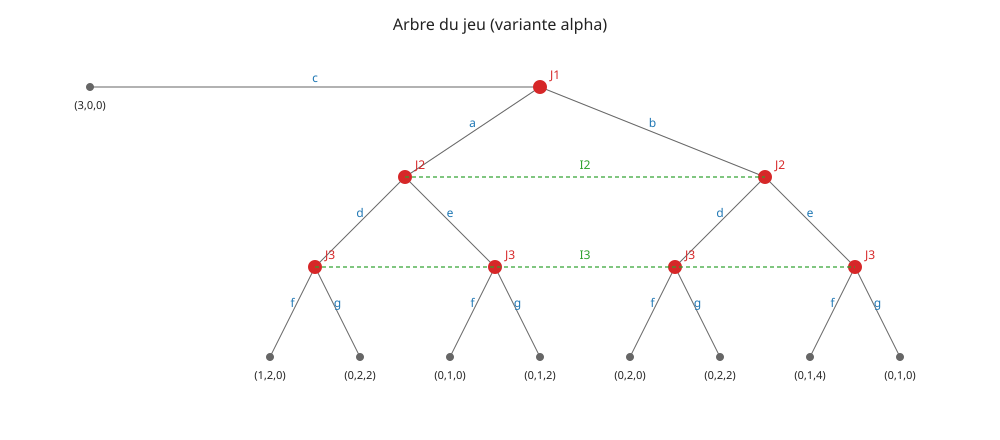

Trace ASCII de l arbre (meme information que la figure) :


()  J1 [I1]


├─ a → ('a')  J2 [I2]


│  ├─ d → ('a', 'd')  J3 [I3]


│  │  ├─ f → ('a', 'd', 'f')  (1,2,0)


│  │  └─ g → ('a', 'd', 'g')  (0,2,2)


... (11 outputs left out)

Ensembles d'information :


  I1 : [()]


  I2 : [('a'), ('b')]


  I3 : [('a', 'd'), ('a', 'e'), ('b', 'd'), ('b', 'e')]


In [3]:
// Dessin de l'arbre et ensembles d'information
// La figure est un SVG produit par le carnet lui-meme (aucune dependance
// graphique externe) ; elle est affichee ci-dessous dans la sortie, et le
// trace ASCII ainsi que la liste des ensembles d'information en donnent la
// lecture immediate dans le carnet. Aucun fichier n'est ecrit sur le disque :
// le carnet ne depend donc d'aucun chemin de machine.

public static Dictionary<string, List<string>> InfoSets()
{
    var res = new Dictionary<string, List<string>>();
    var keys = new List<string>(ARBRE.Keys);
    keys.Sort((x, y) =>
    {
        int c = x.Length.CompareTo(y.Length);
        if (c != 0) { return c; }
        return string.CompareOrdinal(x, y);
    });
    foreach (string h in keys)
    {
        if (ARBRE[h].type != "decision") { continue; }
        string iset = ARBRE[h].infoSet;
        if (!res.ContainsKey(iset)) { res[iset] = new List<string>(); }
        res[iset].Add(h);
    }
    return res;
}

public static Dictionary<string, (double x, double y)> Coordonnees()
{
    var xs = new Dictionary<string, double>
    {
        { "", 4.0 }, { "a", 2.5 }, { "b", 6.5 }, { "c", -1.0 },
        { "a|d", 1.5 }, { "a|e", 3.5 }, { "b|d", 5.5 }, { "b|e", 7.5 },
        { "a|d|f", 1.0 }, { "a|d|g", 2.0 }, { "a|e|f", 3.0 }, { "a|e|g", 4.0 },
        { "b|d|f", 5.0 }, { "b|d|g", 6.0 }, { "b|e|f", 7.0 }, { "b|e|g", 8.0 },
    };
    var ys = new Dictionary<string, double> { { "", 3.0 }, { "a", 2.0 }, { "b", 2.0 }, { "c", 3.0 } };
    foreach (string h in new[] { "a|d", "a|e", "b|d", "b|e" })
    {
        ys[h] = 1.0;
        ys[h + "|f"] = 0.0;
        ys[h + "|g"] = 0.0;
    }
    var res = new Dictionary<string, (double x, double y)>();
    foreach (var kv in xs) { res[kv.Key] = (kv.Value, ys[kv.Key]); }
    return res;
}

public static string Att(string nom, double v)
{
    return nom + "=\"" + Num(v, "F1") + "\"";
}

public static string DessinerArbreSvg(Dictionary<string, (int u1, int u2, int u3)> payoffs, string titre)
{
    var co = Coordonnees();
    Func<double, double> px = v => 90.0 + (v + 1.0) * 90.0;
    Func<double, double> py = v => 60.0 + (3.3 - v) * 90.0;
    var sb = new System.Text.StringBuilder();
    sb.AppendLine("<?xml version=\"1.0\" encoding=\"UTF-8\"?>");
    sb.AppendLine("<svg xmlns=\"http://www.w3.org/2000/svg\" width=\"1000\" height=\"440\" viewBox=\"0 0 1000 440\">");
    sb.AppendLine("  <rect x=\"0\" y=\"0\" width=\"1000\" height=\"440\" fill=\"#ffffff\"/>");
    sb.AppendLine("  <text x=\"500\" y=\"30\" font-family=\"sans-serif\" font-size=\"16\" text-anchor=\"middle\" fill=\"#222222\">" + titre + "</text>");

    // aretes et etiquettes d'action
    foreach (var kv in ARBRE)
    {
        string h = kv.Key;
        var noeud = kv.Value;
        if (noeud.type != "decision") { continue; }
        foreach (var (action, enfant) in noeud.enfants)
        {
            double x1 = px(co[h].x), y1 = py(co[h].y), x2 = px(co[enfant].x), y2 = py(co[enfant].y);
            sb.AppendLine("  <line " + Att("x1", x1) + " " + Att("y1", y1) + " " + Att("x2", x2) + " " + Att("y2", y2) + " stroke=\"#666666\" stroke-width=\"1\"/>");
            sb.AppendLine("  <text x=\"" + Num((x1 + x2) / 2.0, "F1") + "\" y=\"" + Num((y1 + y2) / 2.0 - 5.0, "F1") + "\" font-family=\"sans-serif\" font-size=\"12\" text-anchor=\"middle\" fill=\"#1f77b4\">" + action + "</text>");
        }
    }

    // noeuds, payoffs et identifiants de joueur
    foreach (var kv in ARBRE)
    {
        string h = kv.Key;
        var noeud = kv.Value;
        double cx = px(co[h].x), cy = py(co[h].y);
        if (noeud.type == "terminal")
        {
            sb.AppendLine("  <circle " + Att("cx", cx) + " " + Att("cy", cy) + " r=\"4\" fill=\"#666666\"/>");
            var p = payoffs[h];
            sb.AppendLine("  <text x=\"" + Num(cx, "F1") + "\" y=\"" + Num(cy + 22.0, "F1") + "\" font-family=\"sans-serif\" font-size=\"11\" text-anchor=\"middle\" fill=\"#222222\">(" + p.u1 + "," + p.u2 + "," + p.u3 + ")</text>");
        }
        else
        {
            sb.AppendLine("  <circle " + Att("cx", cx) + " " + Att("cy", cy) + " r=\"7\" fill=\"#d62728\"/>");
            sb.AppendLine("  <text x=\"" + Num(cx + 10.0, "F1") + "\" y=\"" + Num(cy - 8.0, "F1") + "\" font-family=\"sans-serif\" font-size=\"12\" fill=\"#d62728\">J" + noeud.joueur + "</text>");
        }
    }

    // ensembles d'information (liaisons en pointilles)
    foreach (var kv in InfoSets())
    {
        var hs = kv.Value;
        if (hs.Count <= 1) { continue; }
        double xmin = double.MaxValue, xmax = double.MinValue, y0 = 0.0, y1 = 0.0;
        for (int i = 0; i < hs.Count; i++)
        {
            double cx = co[hs[i]].x;
            if (cx < xmin) { xmin = cx; }
            if (cx > xmax) { xmax = cx; }
            if (i == 0) { y0 = co[hs[i]].y; }
            if (i == hs.Count - 1) { y1 = co[hs[i]].y; }
        }
        sb.AppendLine("  <line " + Att("x1", px(xmin)) + " " + Att("y1", py(y0)) + " " + Att("x2", px(xmax)) + " " + Att("y2", py(y1)) + " stroke=\"#2ca02c\" stroke-width=\"1.2\" stroke-dasharray=\"4 3\"/>");
        sb.AppendLine("  <text x=\"" + Num((px(xmin) + px(xmax)) / 2.0, "F1") + "\" y=\"" + Num(py(y0) - 8.0, "F1") + "\" font-family=\"sans-serif\" font-size=\"12\" text-anchor=\"middle\" fill=\"#2ca02c\">" + kv.Key + "</text>");
    }

    sb.AppendLine("</svg>");
    return sb.ToString();
}

public static void AfficherArbreAscii(Dictionary<string, (int u1, int u2, int u3)> payoffs, string h, string action, string prefix, bool dernier, bool racine)
{
    var noeud = ARBRE[h];
    if (racine)
    {
        Console.WriteLine(FormatHist(h) + "  J" + noeud.joueur + " [" + noeud.infoSet + "]");
    }
    else if (noeud.type == "terminal")
    {
        var p = payoffs[h];
        Console.WriteLine(prefix + (dernier ? "└─ " : "├─ ") + action + " → " + FormatHist(h) + "  (" + p.u1 + "," + p.u2 + "," + p.u3 + ")");
    }
    else
    {
        Console.WriteLine(prefix + (dernier ? "└─ " : "├─ ") + action + " → " + FormatHist(h) + "  J" + noeud.joueur + " [" + noeud.infoSet + "]");
    }
    if (noeud.type != "decision") { return; }
    string nextPrefix = racine ? "" : prefix + (dernier ? "   " : "│  ");
    var enfants = noeud.enfants;
    for (int i = 0; i < enfants.Length; i++)
    {
        AfficherArbreAscii(payoffs, enfants[i].enfant, enfants[i].action, nextPrefix, i == enfants.Length - 1, false);
    }
}

string svg = DessinerArbreSvg(PAYOFFS_ALPHA, "Arbre du jeu (variante alpha)");
Console.WriteLine("Figure SVG (arbre, payoffs, ensembles d'information) : " + svg.Length + " caracteres, " + svg.Split('\n').Length + " lignes");
svg.DisplayAs("image/svg+xml");
Console.WriteLine();
Console.WriteLine("Trace ASCII de l arbre (meme information que la figure) :");
AfficherArbreAscii(PAYOFFS_ALPHA, "", "", "", true, true);
Console.WriteLine();
Console.WriteLine("Ensembles d'information :");
foreach (var kv in InfoSets())
{
    var noms = new List<string>();
    foreach (string h in kv.Value) { noms.Add(FormatHist(h)); }
    Console.WriteLine("  " + kv.Key + " : [" + string.Join(", ", noms) + "]");
}


### 1.2 Assessment et rationalite sequentielle

Un **assessment** est un couple $(\sigma, \mu)$ : une strategie de comportement (une probabilite sur les actions de chaque ensemble d'information) et un systeme de croyances (une distribution sur les noeuds de chaque ensemble d'information).

> **Definition 10.2 (Bonanno).** $\sigma$ est *sequentiellement rationnelle* si, a **chaque** ensemble d'information $H$, le joueur ne peut pas augmenter son paiement conditionnel en changeant son choix en $H$ **et** en tout ensemble d'information futur qu'il controle.

La clause « et en tout ensemble futur » est la partie qu'on oublie, et c'est elle qui fait la force de la notion. Bonanno l'illustre (Fig. 10.2) : une strategie $(c, e)$ peut etre localement optimale en $\{x,y\}$ — donc optimale dans chaque ensemble pris isolement — et pourtant battue si le joueur change **aussi** son plan en $\{s,t\}$. Retenir « localement optimal » donnerait un faux raffinement ; la definition exige un changement de strategie **entiere**.

In [4]:
// Moteur d'evaluation sequentielle
// sigma est un Dictionary<(ensemble d'information, action), probabilite> ;
// mu est un Dictionary<historique, croyance> ou null signifie « ensemble
// d'information non atteint » (croyance libre).

// Payoff attendu par induction sur l'arbre : un noeud de decision somme
// sigma(iset, action) * payoff du sous-arbre enfant ; la valeur d'un noeud
// terminal se lit directement dans la table des paiements (u1, u2, u3).
public static double PayoffEspere(string h, int joueur, Dictionary<(string iset, string action), double> sigma, Dictionary<string, (int u1, int u2, int u3)> payoffs)
{
    var noeud = ARBRE[h];
    if (noeud.type == "terminal")
    {
        var p = payoffs[h];
        if (joueur == 1) { return p.u1; }
        if (joueur == 2) { return p.u2; }
        return p.u3;
    }
    double total = 0.0;
    foreach (var (action, enfant) in noeud.enfants)
    {
        total += sigma[(noeud.infoSet, action)] * PayoffEspere(enfant, joueur, sigma, payoffs);
    }
    return total;
}

// Probabilite d'atteindre h sous sigma : produit des probabilites le long du
// chemin. Le separateur "|" encode l'historique ; la racine est la chaine vide.
public static double ProbaAtteinte(string h, Dictionary<(string iset, string action), double> sigma)
{
    double p = 1.0;
    string[] parts = h.Length == 0 ? new string[0] : h.Split('|');
    string prefix = "";
    for (int i = 0; i < parts.Length; i++)
    {
        string iset = ARBRE[prefix].infoSet;
        p *= sigma[(iset, parts[i])];
        prefix = prefix.Length == 0 ? parts[i] : prefix + "|" + parts[i];
    }
    return p;
}

// Croyances bayesiennes : mu(h) = P(h) / somme des P(h') sur l'ensemble
// d'information de h. Ensemble non atteint (somme nulle) : mu = null,
// c'est-a-dire croyance LIBRE -- le moteur du census des WSE s'en servira.
public static Dictionary<string, double?> CroyancesBayesiennes(Dictionary<(string iset, string action), double> sigma)
{
    var mu = new Dictionary<string, double?>();
    foreach (var kv in InfoSets())
    {
        var hs = kv.Value;
        double total = 0.0;
        foreach (string h in hs) { total += ProbaAtteinte(h, sigma); }
        foreach (string h in hs)
        {
            mu[h] = total > 1e-12 ? (double?)(ProbaAtteinte(h, sigma) / total) : null;
        }
    }
    return mu;
}

public static List<(string infoSet, Dictionary<string, double> valeurs, double ecart)> SeqRationnel(
    Dictionary<(string iset, string action), double> sigma,
    Dictionary<string, double?> mu,
    Dictionary<string, (int u1, int u2, int u3)> payoffs,
    double tol = 1e-9)
{
    var violations = new List<(string infoSet, Dictionary<string, double> valeurs, double ecart)>();
    foreach (var kv in InfoSets())
    {
        string iset = kv.Key;
        var hs = kv.Value;
        int joueur = ARBRE[hs[0]].joueur;
        var actions = new List<string>();
        foreach (var (action, _) in ARBRE[hs[0]].enfants) { actions.Add(action); }

        var valeurs = new Dictionary<string, double>();
        foreach (string a in actions)
        {
            double v = 0.0;
            foreach (string h in hs)
            {
                double m = 0.0;
                if (mu.TryGetValue(h, out var mv) && mv.HasValue) { m = mv.Value; }
                v += m * PayoffEspere(h + "|" + a, joueur, sigma, payoffs);
            }
            valeurs[a] = v;
        }

        double melange = 0.0;
        foreach (string a in actions) { melange += sigma[(iset, a)] * valeurs[a]; }
        double max = double.NegativeInfinity;
        foreach (var v in valeurs.Values) { if (v > max) { max = v; } }
        double ecart = max - melange;
        if (ecart > tol) { violations.Add((iset, valeurs, ecart)); }
    }
    return violations;
}

public static Dictionary<(string iset, string action), double> SigmaDepuis(Dictionary<string, string> choix)
{
    var sigma = new Dictionary<(string iset, string action), double>();
    foreach (var kv in InfoSets())
    {
        string iset = kv.Key;
        foreach (var (action, _) in ARBRE[kv.Value[0]].enfants)
        {
            sigma[(iset, action)] = (choix[iset] == action) ? 1.0 : 0.0;
        }
    }
    return sigma;
}

Console.WriteLine("Moteur charge : PayoffEspere, ProbaAtteinte, CroyancesBayesiennes, SeqRationnel, SigmaDepuis");
Console.WriteLine("Ensembles d'information de l'arbre :");
foreach (var kv in InfoSets())
{
    var noms = new List<string>();
    foreach (string h in kv.Value) { noms.Add(FormatHist(h)); }
    Console.WriteLine("  " + kv.Key + " (" + kv.Value.Count + " noeuds) : [" + string.Join(", ", noms) + "]");
}

Moteur charge : PayoffEspere, ProbaAtteinte, CroyancesBayesiennes, SeqRationnel, SigmaDepuis


Ensembles d'information de l'arbre :


  I1 (1 noeuds) : [()]


  I2 (2 noeuds) : [('a'), ('b')]


  I3 (4 noeuds) : [('a', 'd'), ('a', 'e'), ('b', 'd'), ('b', 'e')]


## 2. Un premier assessment : `(c, d, f)` avec la croyance `be` certaine

Prenons $\sigma = (c,\ d,\ f)$ — J1 termine, J2 joue `d`, J3 joue `f` — et posons $\mu(be) = 1$ : J3 croit dur comme fer qu'il se trouve en `be`. C'est le genre de croyance qu'aucune observation ne peut lui fournir, puisque le jeu s'arrete en `c` ; mais rien, dans la definition d'un WSE, ne l'interdit.

Verifions ce que les paiements disent. Sur la variante $\alpha$, J3 prefere `g` en `ad`, `ae` et `bd` ($2 > 0$) ; en `be` il prefere `f` ($4 > 0$). Sa croyance `be` certaine rend donc `f` optimal, et le profil passe le test de rationalite sequentielle.

In [5]:
// Assessment A : croyances et rationalite sequentielle
// Assessment A = (sigma_A ; mu_A) : le profil pur (c, d, f) porte la croyance
// mu(be) = 1 sur le dernier ensemble d'information. Seule l'entree I3 est
// hors du chemin d'equilibre ; Bayes repond None sur I2 et I3 sous sigma_A.
public static class MoteurEval
{
    public static string Hist(string h, string a) => h.Length == 0 ? a : h + "|" + a;

    public static double Payoff(string h, int j, Dictionary<(string iset, string action), double> sigma, Dictionary<string, (int u1, int u2, int u3)> payoffs)
    {
        var n = ARBRE[h];
        if (n.type == "terminal")
        {
            var p = payoffs[h];
            return j == 1 ? p.u1 : j == 2 ? p.u2 : p.u3;
        }
        double v = 0.0;
        foreach (var (a, e) in n.enfants) { v += sigma[(n.infoSet, a)] * Payoff(e, j, sigma, payoffs); }
        return v;
    }

    public static double Atteinte(string h, Dictionary<(string iset, string action), double> sigma)
    {
        double p = 1.0;
        string prefix = "";
        if (h.Length > 0)
        {
            foreach (string a in h.Split('|'))
            {
                p *= sigma[(ARBRE[prefix].infoSet, a)];
                prefix = Hist(prefix, a);
            }
        }
        return p;
    }

    public static Dictionary<string, double?> Bayes(Dictionary<(string iset, string action), double> sigma)
    {
        var mu = new Dictionary<string, double?>();
        foreach (var kv in InfoSets())
        {
            double z = kv.Value.Sum(h => Atteinte(h, sigma));
            foreach (string h in kv.Value) { mu[h] = z > 1e-12 ? (double?)(Atteinte(h, sigma) / z) : null; }
        }
        return mu;
    }

    public static List<(string iset, Dictionary<string, double> valeurs, double ecart)> Seq(Dictionary<(string iset, string action), double> sigma, Dictionary<string, double?> mu, Dictionary<string, (int u1, int u2, int u3)> payoffs)
    {
        var outp = new List<(string, Dictionary<string, double>, double)>();
        foreach (var kv in InfoSets())
        {
            var hs = kv.Value;
            int j = ARBRE[hs[0]].joueur;
            var actions = ARBRE[hs[0]].enfants.Select(x => x.action).ToList();
            var vals = actions.ToDictionary(a => a, a => hs.Sum(h => (mu[h] ?? 0.0) * Payoff(Hist(h, a), j, sigma, payoffs)));
            double mix = actions.Sum(a => sigma[(kv.Key, a)] * vals[a]);
            double ecart = vals.Values.Max() - mix;
            if (ecart > 1e-9) { outp.Add((kv.Key, vals, ecart)); }
        }
        return outp;
    }

    public static Dictionary<(string iset, string action), double> Sigma(Dictionary<string, string> choix)
    {
        var s = new Dictionary<(string, string), double>();
        foreach (var kv in InfoSets())
        {
            foreach (var (a, _) in ARBRE[kv.Value[0]].enfants) { s[(kv.Key, a)] = choix[kv.Key] == a ? 1.0 : 0.0; }
        }
        return s;
    }
}

public static class State
{
    public static Dictionary<(string iset, string action), double> SIGMA_A = MoteurEval.Sigma(new Dictionary<string, string> { { "I1", "c" }, { "I2", "d" }, { "I3", "f" } });
    public static Dictionary<string, double?> MU_A = new Dictionary<string, double?>();
    static State()
    {
        foreach (var kv in InfoSets()) { foreach (string h in kv.Value) { MU_A[h] = h == "b|e" ? (double?)1.0 : (double?)0.0; } }
    }
}

Console.WriteLine("Croyances de A :");
foreach (var kv in State.MU_A) { Console.WriteLine("  " + FormatHist(kv.Key) + " -> " + (kv.Value.HasValue ? Num(kv.Value.Value) : "None")); }
Console.WriteLine("\nBayes sous sigma_A (None = non atteint) :");
foreach (var kv in MoteurEval.Bayes(State.SIGMA_A)) { Console.WriteLine("  " + FormatHist(kv.Key) + " -> " + (kv.Value.HasValue ? Num(kv.Value.Value) : "None")); }
var violations = MoteurEval.Seq(State.SIGMA_A, State.MU_A, PAYOFFS_ALPHA);
Console.WriteLine("\nViolations de rationalite sequentielle : " + (violations.Count == 0 ? "aucune" : violations.Count.ToString()));
// Detail des valeurs au dernier ensemble d'information : comparer la valeur
// de l'action jouee au max des valeurs alternatives dit, croyance par
// croyance, si la rationalite sequentielle tient.
Console.WriteLine("\nDetail des valeurs au dernier ensemble d'information :");
foreach (var kv in InfoSets())
{
    var actions = ARBRE[kv.Value[0]].enfants.Select(x => x.action).ToList();
    int j = ARBRE[kv.Value[0]].joueur;
    var vals = actions.ToDictionary(a => a, a => kv.Value.Sum(h => (State.MU_A[h] ?? 0.0) * MoteurEval.Payoff(MoteurEval.Hist(h, a), j, State.SIGMA_A, PAYOFFS_ALPHA)));
    string joue = actions.First(a => State.SIGMA_A[(kv.Key, a)] > 0);
    Console.WriteLine("  " + kv.Key + " (J" + j + ") : {" + string.Join(", ", vals.Select(x => x.Key + "=" + Num(x.Value, "F3"))) + "} -> joue " + joue);
}

Croyances de A :


  () -> 0.0000


  ('a') -> 0.0000


  ('b') -> 0.0000


  ('a', 'd') -> 0.0000


  ('a', 'e') -> 0.0000


... (11 outputs left out)


Detail des valeurs au dernier ensemble d'information :


  I1 (J1) : {a=0.000, b=0.000, c=0.000} -> joue c


  I2 (J2) : {d=0.000, e=0.000} -> joue d


  I3 (J3) : {f=4.000, g=0.000} -> joue f


### 2.1 La definition du WSE

> **Definition 10.4 (Bonanno).** $\mu$ est *bayesiennement coherent* avec $\sigma$ si, pour tout ensemble d'information $H$ **atteint avec probabilite positive**, $\mu(x) = P^{\sigma}(x) / P^{\sigma}(H)$.
>
> **Definition 10.5.** Un **equilibre sequentiel faible** est un assessment sequentiellement rationnel dont les croyances sont bayesiennement coherentes.

Le mot decisif est « atteint ». Hors du chemin, $\mu$ est **libre** : la definition ne lui impose rien. C'est exactement la porte par laquelle passe l'assessment `A`, et c'est aussi la faiblesse que le chapitre 11 va refermer.

Cherchons maintenant **tous** les WSE purs du jeu, en laissant le programme faire le travail : pour chaque profil pur, on calcule les croyances imposees par Bayes la ou le jeu passe, et on cherche, sur une grille, des croyances libres qui rendent le profil sequentiellement rationnel.

In [6]:
// Grille du simplexe et census des WSE purs
public static class WseCensus
{
    // Grille du simplexe au pas demande : toutes les repartitions entieres de
// l'unite entre les noeuds de l'ensemble, generees comme combinaisons avec
// repetition puis normalisees par k = 1/pas (pas 1/4 : 0, 1/4, ..., 1).
public static IEnumerable<double[]> GrilleSimplexe(int n, double pas = 0.25)
    {
        int k = (int)Math.Round(1.0 / pas);
        if (n == 1)
        {
            yield return new[] { 1.0 };
            yield break;
        }
        foreach (int[] c in Combinaisons(k + 1, n - 1))
        {
            int somme = c.Sum();
            if (somme <= k)
            {
                yield return c.Select(x => (double)x / k)
                    .Concat(new[] { (double)(k - somme) / k })
                    .ToArray();
            }
        }
    }

    private static IEnumerable<int[]> Combinaisons(int nombreValeurs, int longueur)
    {
        int[] courante = new int[longueur];
        return CombinaisonsAux(nombreValeurs, courante, 0);
    }

    private static IEnumerable<int[]> CombinaisonsAux(int nombreValeurs, int[] courante, int position)
    {
        if (position == courante.Length)
        {
            yield return (int[])courante.Clone();
            yield break;
        }
        for (int v = 0; v < nombreValeurs; v++)
        {
            courante[position] = v;
            foreach (int[] suite in CombinaisonsAux(nombreValeurs, courante, position + 1))
            {
                yield return suite;
            }
        }
    }

    private static IEnumerable<int[]> IndicesRecursifs(List<List<double[]>> grilles, int position)
    {
        if (position == grilles.Count)
        {
            yield return new int[grilles.Count];
            yield break;
        }
        for (int i = 0; i < grilles[position].Count; i++)
        {
            foreach (int[] suite in IndicesRecursifs(grilles, position + 1))
            {
                suite[position] = i;
                yield return suite;
            }
        }
    }

    // Un WSE n'exige la rationalite sequentielle que pour les croyances LIBRES :
// Bayes fixe mu sur les ensembles atteints ; les non-atteints sont testes
// sur toute la grille du simplexe. UNE croyance qui rend sigma rationnel
// suffit a valider le profil -- le temoin correspondant est retourne avec
// le verdict pour inspection.
public static (bool wse, Dictionary<string, double?> mu) EstWse(
        Dictionary<(string iset, string action), double> sigma,
        Dictionary<string, (int u1, int u2, int u3)> payoffs,
        double pas = 0.25)
    {
        Dictionary<string, double?> baseMu = MoteurEval.Bayes(sigma);
        Dictionary<string, List<string>> sets = InfoSets();
        List<string> libres = sets.Where(kv => !baseMu[kv.Value[0]].HasValue)
            .Select(kv => kv.Key).ToList();
        List<List<double[]>> grilles = libres
            .Select(i => GrilleSimplexe(sets[i].Count, pas).ToList())
            .ToList();

        IEnumerable<int[]> indices = grilles.Count == 0
            ? new[] { new int[0] }
            : IndicesRecursifs(grilles, 0);

        foreach (int[] ix in indices)
        {
            Dictionary<string, double?> mu = baseMu.ToDictionary(x => x.Key, x => x.Value);
            for (int i = 0; i < libres.Count; i++)
            {
                double[] valeurs = grilles[i][ix[i]];
                for (int j = 0; j < sets[libres[i]].Count; j++)
                {
                    mu[sets[libres[i]][j]] = valeurs[j];
                }
            }
            if (MoteurEval.Seq(sigma, mu, payoffs).Count == 0)
            {
                return (true, mu);
            }
        }
        return (false, null);
    }

    public static List<(string profil, Dictionary<string, double?> mu)> WsePurs =
        new List<(string profil, Dictionary<string, double?> mu)>();
}

// Census des 12 profils purs : 3 x 2 x 2 choix deterministes sur (I1, I2, I3).
WseCensus.WsePurs.Clear();
foreach (string x in new[] { "a", "b", "c" })
foreach (string y in new[] { "d", "e" })
foreach (string z in new[] { "f", "g" })
{
    string profil = x + y + z;
    Dictionary<(string iset, string action), double> sigma = MoteurEval.Sigma(
        new Dictionary<string, string> { { "I1", x }, { "I2", y }, { "I3", z } });
    (bool wse, Dictionary<string, double?> mu) resultat = WseCensus.EstWse(sigma, PAYOFFS_ALPHA);
    if (resultat.wse)
    {
        WseCensus.WsePurs.Add((profil, resultat.mu));
    }
}

Console.WriteLine(WseCensus.WsePurs.Count + " equilibres sequentiels faibles purs sur 12 profils :");
foreach (var (profil, mu) in WseCensus.WsePurs)
{
    Dictionary<string, double> porteuses = mu
        .Where(x => x.Value.HasValue && x.Value.Value > 0)
        .ToDictionary(x => x.Key, x => x.Value.Value);
    Console.WriteLine("  sigma = " + profil.PadRight(3) + "  croyances porteuses : {" +
        string.Join(", ", porteuses.Select(x => FormatHist(x.Key) + "=" + Num(x.Value, "F2"))) + "}");
}

2 equilibres sequentiels faibles purs sur 12 profils :


  sigma = cdf  croyances porteuses : {()=1.00, ('b')=1.00, ('b', 'e')=1.00}


  sigma = cdg  croyances porteuses : {()=1.00, ('b')=1.00, ('b', 'd')=0.75, ('b', 'e')=0.25}


### 2.2 Ce que le WSE accepte

Deux choses sont a lire dans cette enumeration.

**Le WSE est permissif hors du chemin.** Le profil `cdf` passe avec $\mu(be) = 1$ : l'ensemble d'information n'est jamais atteint, donc Bayes ne dit rien, et la rationalite sequentielle se satisfait d'**une** croyance favorable. Un equilibre qui repose sur une croyance qu'aucune histoire du jeu ne produirait peut donc rester un WSE parfaitement legal — **a condition que cette croyance soit favorable**. Cette permissivite est **bornee** : la section 2.4 montre que `cdf` n'est un WSE que si $\mu(be) \ge 1/3$ ; une croyance hors du chemin et *defavorable* n'est pas un WSE.

**Le WSE n'est pas une variante du SPE.** Bonanno (Fig. 10.9) donne un jeu ou un WSE n'est pas sous-jeu parfait, et la Fig. 10.8 un SPE qui n'est aucun WSE : les deux ensembles se croisent sans contenir l'un l'autre. Un WSE n'implique pas de credibilite dans les sous-jeux, un SPE ne dit rien des croyances aux ensembles d'information qui ne sont pas des sous-jeux. Ce carnet ne peut pas montrer ce croisement sur son arbre (il n'a aucun sous-jeu propre) : c'est un resultat cite, que le chapitre 10 etablit sur des arbres a deux branches.

### 2.3 La frontiere exacte : ce que la grille ne peut pas voir

La grille de la cellule precedente explore les croyances libres au pas `1/4`. Elle repond a une question de **compte** — quels profils sont des WSE ? — et non a la question **geometrique** : quelles croyances rendent un profil admissible ?

Les deux ne se traitent pas de la meme facon. Sous un profil **pur**, la continuation est deterministe : l'ecart de rationalite sequentielle entre l'action choisie et une action alternative ne depend plus que de l'historique, par un **coefficient entier**. La condition de rationalite devient donc une **inegalite lineaire** en les seules croyances libres :

$$
\sum_h c_h\,\ \mu(h) \;\ge\; 0 .
$$

Un ensemble d'information **atteint** ne laisse aucun choix : la contrainte est une **constante**, vraie ou fausse. Un ensemble d'information **libre** laisse un choix : la partie libre de la somme parcourt le **simplexe** (somme 1 sur ses historiques), donc la contrainte ne definit pas un point mais une **demi-espace** — une frontiere.

C'est la que la grille s'arrete. Une frontiere peut tomber **entre** deux points de la grille : une grille ne peut alors ni l'exprimer, ni s'y poser.


In [7]:
// Census exact des 12 profils purs et frontiere mu(be) = 1/3
public static class ExactCensus
{
    public static int UExact(string h, int joueur, Dictionary<(string iset, string action), double> sigma)
    {
        var noeud = ARBRE[h];
        if (noeud.type == "terminal")
        {
            var p = PAYOFFS_ALPHA[h];
            return joueur == 1 ? p.u1 : joueur == 2 ? p.u2 : p.u3;
        }
        var choisi = noeud.enfants.First(x => sigma[(noeud.infoSet, x.action)] == 1.0);
        return UExact(choisi.enfant, joueur, sigma);
    }

    // Ecarts d'utilite exacts (payoffs entiers) entre l'action choisie et chaque
// alternative, noeud par noeud de l'ensemble d'information : le WSE exact
// raisonne sur ces ecarts sans re-executer de payoff espere.
public static Dictionary<string, Dictionary<string, int>> Ecarts(
        string iset,
        int joueur,
        Dictionary<(string iset, string action), double> sigma)
    {
        List<string> hs = InfoSets()[iset];
        string actionChoisie = ARBRE[hs[0]].enfants
            .First(x => sigma[(iset, x.action)] == 1.0).action;
        var resultat = new Dictionary<string, Dictionary<string, int>>();
        foreach (var alternative in ARBRE[hs[0]].enfants.Where(x => x.action != actionChoisie))
        {
            resultat[alternative.action] = hs.ToDictionary(
                h => h,
                h => UExact(MoteurEval.Hist(h, actionChoisie), joueur, sigma)
                   - UExact(MoteurEval.Hist(h, alternative.action), joueur, sigma));
        }
        return resultat;
    }

    // Faisabilite : sur un ensemble ATTEINT, la contrainte est une constante ;
// sur un ensemble LIBRE, elle devient lineaire en mu et se satisfait a la
// frontiere (d'ou le seuil mu(be) = 1/3 du titre de la cellule).
public static bool Faisable(
        string iset,
        int joueur,
        Dictionary<(string iset, string action), double> sigma,
        Dictionary<string, double?> baseMu)
    {
        List<string> hs = InfoSets()[iset];
        Dictionary<string, Dictionary<string, int>> ecarts = Ecarts(iset, joueur, sigma);
        foreach (Dictionary<string, int> contrainte in ecarts.Values)
        {
            if (baseMu[hs[0]].HasValue)
            {
                // Ensemble ATTEINT : la contrainte est une constante, vraie ou fausse.
                double valeur = hs.Sum(h => baseMu[h].Value * contrainte[h]);
                if (valeur < 0) { return false; }
            }
            else if (ecarts.Count > 1)
            {
                // Plusieurs actions alternatives sur un ensemble LIBRE : cas non couvert ici.
                return false;
            }
            else
            {
                // Ensemble LIBRE : la contrainte est faisable ssi sa borne haute est non negative.
                if (contrainte.Values.Max() < 0) { return false; }
            }
        }
        return true;
    }

    // Etiquette courte d'un historique : "a|d" devient "ad".
    public static string Etiq(string h)
    {
        return h.Replace("|", "");
    }

    public static string Forme(string profil, Dictionary<(string iset, string action), double> sigma)
    {
        Dictionary<string, int> c = Ecarts("I3", 3, sigma).Values.First();
        return string.Join(" ", c.Select(x =>
            (x.Value >= 0 ? "+" : "") + x.Value + "*mu[" + Etiq(x.Key) + "]"));
    }

    // Diagnostic par ensemble d'information : type (fixe / libre) et ecart signe.
    public static List<string> Diagnostic(
        Dictionary<(string iset, string action), double> sigma,
        Dictionary<string, double?> baseMu)
    {
        var lignes = new List<string>();
        foreach (var kv in InfoSets())
        {
            string iset = kv.Key;
            List<string> hs = kv.Value;
            int joueur = ARBRE[hs[0]].joueur;
            string choisie = ARBRE[hs[0]].enfants.First(x => sigma[(iset, x.action)] == 1.0).action;
            bool atteint = baseMu[hs[0]].HasValue;
            Dictionary<string, Dictionary<string, int>> ecarts = Ecarts(iset, joueur, sigma);
            foreach (var alternative in ARBRE[hs[0]].enfants.Where(x => x.action != choisie))
            {
                Dictionary<string, int> c = ecarts[alternative.action];
                string forme = string.Join(" ", c.Select(x =>
                    (x.Value >= 0 ? "+" : "") + x.Value + "*mu[" + Etiq(x.Key) + "]"));
                if (atteint)
                {
                    double valeur = 0.0;
                    foreach (string h in hs)
                    {
                        if (baseMu[h].HasValue) { valeur += baseMu[h].Value * c[h]; }
                    }
                    lignes.Add(iset + " [fixe]  ecart " + choisie + " - " + alternative.action +
                        " = " + Num(valeur, "F2") + "  (exigence : " + choisie + " >= " + alternative.action +
                        ")  -> " + (valeur >= 0 ? "satisfaite" : "VIOLATION"));
                }
                else
                {
                    bool faisable = c.Values.Max() >= 0;
                    lignes.Add(iset + " [libre]  contrainte " + forme + " >= 0  -> " +
                        (faisable ? "faisable" : "impossible"));
                }
            }
        }
        return lignes;
    }

    public static (string sens, double seuil) SeuilMuBe(
        string profil,
        Dictionary<(string iset, string action), double> sigma)
    {
        Dictionary<string, int> c = Ecarts("I3", 3, sigma).Values.First();
        int cBe = c["b|e"];
        int autres = c.Where(x => x.Key != "b|e").Select(x => x.Value).Distinct().Single();
        double seuil = -autres / (double)(cBe - autres);
        return (cBe > autres ? ">=" : "<=", seuil);
    }

    // Grille du simplexe, recalculee ici pour rendre la cellule autonome.
    public static IEnumerable<double[]> GrilleSimplexe(int n, double pas)
    {
        int k = (int)Math.Round(1.0 / pas);
        if (n == 1)
        {
            yield return new[] { 1.0 };
            yield break;
        }
        foreach (int[] c in Combinaisons(k + 1, n - 1))
        {
            int somme = c.Sum();
            if (somme <= k)
            {
                yield return c.Select(x => (double)x / k)
                    .Concat(new[] { (double)(k - somme) / k })
                    .ToArray();
            }
        }
    }

    private static IEnumerable<int[]> Combinaisons(int nombreValeurs, int longueur)
    {
        int[] courante = new int[longueur];
        return CombinaisonsAux(nombreValeurs, courante, 0);
    }

    private static IEnumerable<int[]> CombinaisonsAux(int nombreValeurs, int[] courante, int position)
    {
        if (position == courante.Length)
        {
            yield return (int[])courante.Clone();
            yield break;
        }
        for (int v = 0; v < nombreValeurs; v++)
        {
            courante[position] = v;
            foreach (int[] suite in CombinaisonsAux(nombreValeurs, courante, position + 1))
            {
                yield return suite;
            }
        }
    }

    private static IEnumerable<int[]> IndicesRecursifs(List<List<double[]>> grilles, int position)
    {
        if (position == grilles.Count)
        {
            yield return new int[grilles.Count];
            yield break;
        }
        for (int i = 0; i < grilles[position].Count; i++)
        {
            foreach (int[] suite in IndicesRecursifs(grilles, position + 1))
            {
                suite[position] = i;
                yield return suite;
            }
        }
    }

    public static (bool wse, Dictionary<string, double?> mu) EstWseGrille(
        Dictionary<(string iset, string action), double> sigma,
        Dictionary<string, (int u1, int u2, int u3)> payoffs,
        double pas)
    {
        Dictionary<string, double?> baseMu = MoteurEval.Bayes(sigma);
        Dictionary<string, List<string>> sets = InfoSets();
        List<string> libres = sets.Where(kv => !baseMu[kv.Value[0]].HasValue)
            .Select(kv => kv.Key).ToList();
        List<List<double[]>> grilles = libres
            .Select(i => GrilleSimplexe(sets[i].Count, pas).ToList())
            .ToList();
        IEnumerable<int[]> indices = grilles.Count == 0
            ? new[] { new int[0] }
            : IndicesRecursifs(grilles, 0);
        foreach (int[] ix in indices)
        {
            Dictionary<string, double?> mu = baseMu.ToDictionary(x => x.Key, x => x.Value);
            for (int i = 0; i < libres.Count; i++)
            {
                double[] valeurs = grilles[i][ix[i]];
                for (int j = 0; j < sets[libres[i]].Count; j++)
                {
                    mu[sets[libres[i]][j]] = valeurs[j];
                }
            }
            if (MoteurEval.Seq(sigma, mu, payoffs).Count == 0)
            {
                return (true, mu);
            }
        }
        return (false, null);
    }

    public static Dictionary<string, bool> WsePursExacts()
    {
        var resultat = new Dictionary<string, bool>();
        foreach (string x in new[] { "a", "b", "c" })
        foreach (string y in new[] { "d", "e" })
        foreach (string z in new[] { "f", "g" })
        {
            string profil = x + y + z;
            Dictionary<(string iset, string action), double> sigma = MoteurEval.Sigma(
                new Dictionary<string, string> { { "I1", x }, { "I2", y }, { "I3", z } });
            Dictionary<string, double?> baseMu = MoteurEval.Bayes(sigma);
            bool feasible = true;
            foreach (var kv in InfoSets())
            {
                feasible = feasible && Faisable(kv.Key, ARBRE[kv.Value[0]].joueur, sigma, baseMu);
            }
            resultat[profil] = feasible;
        }
        return resultat;
    }
}

Dictionary<string, bool> exact = ExactCensus.WsePursExacts();
Console.WriteLine("Census EXACT des 12 profils purs (contraintes entieres)");
Console.WriteLine(new string('=', 78));
foreach (var kv in exact)
{
    string profil = kv.Key;
    Dictionary<(string iset, string action), double> sigma = MoteurEval.Sigma(
        new Dictionary<string, string>
        {
            { "I1", profil[0].ToString() },
            { "I2", profil[1].ToString() },
            { "I3", profil[2].ToString() }
        });
    Dictionary<string, double?> baseMu = MoteurEval.Bayes(sigma);
    Console.WriteLine("  sigma = " + profil.PadRight(3) + "  " + (kv.Value ? "WSE" : " -") +
        "   toutes les contraintes sont satisfiables : " + kv.Value);
    foreach (string ligne in ExactCensus.Diagnostic(sigma, baseMu))
    {
        Console.WriteLine("      " + ligne);
    }
}

List<string> exacts = exact.Where(x => x.Value).Select(x => x.Key).OrderBy(x => x).ToList();

List<string> grille = new List<string>();
foreach (string x in new[] { "a", "b", "c" })
foreach (string y in new[] { "d", "e" })
foreach (string z in new[] { "f", "g" })
{
    Dictionary<(string iset, string action), double> sigma = MoteurEval.Sigma(
        new Dictionary<string, string> { { "I1", x }, { "I2", y }, { "I3", z } });
    if (ExactCensus.EstWseGrille(sigma, PAYOFFS_ALPHA, 0.25).wse) { grille.Add(x + y + z); }
}
Console.WriteLine("\nWSE purs : census exact [" + string.Join(", ", exacts) +
    "] | grille au pas 1/4 [" + string.Join(", ", grille) + "]");

Dictionary<(string iset, string action), double> sigmaCdf = MoteurEval.Sigma(
    new Dictionary<string, string> { { "I1", "c" }, { "I2", "d" }, { "I3", "f" } });
Dictionary<(string iset, string action), double> sigmaCdg = MoteurEval.Sigma(
    new Dictionary<string, string> { { "I1", "c" }, { "I2", "d" }, { "I3", "g" } });

foreach (string profil in new[] { "cdf", "cdg" })
{
    Dictionary<(string iset, string action), double> sigma = MoteurEval.Sigma(
        new Dictionary<string, string>
        {
            { "I1", profil[0].ToString() },
            { "I2", profil[1].ToString() },
            { "I3", profil[2].ToString() }
        });
    (string sens, double seuil) = ExactCensus.SeuilMuBe(profil, sigma);
    Console.WriteLine("\nsigma = " + profil + " : " + ExactCensus.Forme(profil, sigma) +
        " >= 0  <=>  mu(be) " + sens + " " + Num(seuil, "F6"));

    foreach ((double p, string etiquette) in new[]
    {
        (seuil, "frontiere"),
        (seuil + 0.01, "seuil + 1/100"),
        (seuil - 0.01, "seuil - 1/100"),
        (0.25, "1/4"),
        (0.5, "1/2")
    })
    {
        Dictionary<string, double?> mu = MoteurEval.Bayes(sigma)
            .ToDictionary(x => x.Key, x => x.Value);
        foreach (string h in new[] { "a|d", "a|e", "b|d", "b|e" }) { mu[h] = 0.0; }
        mu["b|e"] = p;
        mu["a|d"] = 1.0 - p;
        mu["a"] = 0.5;
        mu["b"] = 0.5;
        Console.WriteLine("  mu(be)=" + Num(p, "F4").PadRight(8) + " (" + etiquette.PadRight(14) +
            ") -> rationnel : " + (MoteurEval.Seq(sigma, mu, PAYOFFS_ALPHA).Count == 0));
    }
}

Console.WriteLine("\nSur la face mu(be)=1/3, le reste se repartit librement :");
foreach (var (etiquette, part) in new[]
{
    ("tout sur ad", (1.0, 0.0, 0.0)),
    ("tout sur ae", (0.0, 1.0, 0.0)),
    ("tout sur bd", (0.0, 0.0, 1.0)),
    ("ad et ae egaux", (0.5, 0.5, 0.0)),
    ("1/2 1/4 1/4", (0.5, 0.25, 0.25)),
    ("melange 1/3", (1.0 / 3.0, 1.0 / 3.0, 1.0 / 3.0))
})
{
    Dictionary<string, double?> mu = new Dictionary<string, double?>();
    foreach (var kv in InfoSets()) { foreach (string h in kv.Value) { mu[h] = 0.0; } }
    mu["a|d"] = (1.0 / 3.0) * part.Item1;
    mu["a|e"] = (1.0 / 3.0) * part.Item2;
    mu["b|d"] = (1.0 / 3.0) * part.Item3;
    mu["b|e"] = 1.0 / 3.0;
    mu["a"] = 0.5;
    mu["b"] = 0.5;

    Console.WriteLine("  " + etiquette.PadRight(16) +
        " -> cdf: " + (MoteurEval.Seq(sigmaCdf, mu, PAYOFFS_ALPHA).Count == 0) +
        " | cdg: " + (MoteurEval.Seq(sigmaCdg, mu, PAYOFFS_ALPHA).Count == 0));
}

Console.WriteLine("\nHors de la face mu(be) = 1/3 :");
foreach (double p in new[] { 0.25, 0.5 })
{
    Dictionary<string, double?> mu = MoteurEval.Bayes(sigmaCdf)
        .ToDictionary(x => x.Key, x => x.Value);
    foreach (string h in new[] { "a|d", "a|e", "b|d", "b|e" }) { mu[h] = 0.0; }
    mu["a|d"] = 1.0 - p;
    mu["b|e"] = p;
    mu["a"] = 0.5;
    mu["b"] = 0.5;
    Console.WriteLine("  mu(be)=" + Num(p, "F2").PadRight(6) + " -> cdf : " +
        (MoteurEval.Seq(sigmaCdf, mu, PAYOFFS_ALPHA).Count == 0) +
        " | cdg : " + (MoteurEval.Seq(sigmaCdg, mu, PAYOFFS_ALPHA).Count == 0));
}

Console.WriteLine("\n1/3 est-il un multiple de 1/4 ? " + ((1.0 / 3.0 * 4.0) % 1.0 == 0.0));

// Contre-exemple : mu(be) = 0, tout le poids de I3 porte par ad.
// La croyance mu(ad) = 1 rend g strictement meilleur que f (2 contre 0).
Dictionary<string, double?> muZero = new Dictionary<string, double?>();
foreach (var kv in InfoSets()) { foreach (string h in kv.Value) { muZero[h] = 0.0; } }
muZero[""] = 1.0;
muZero["a"] = 0.5;
muZero["b"] = 0.5;
muZero["a|d"] = 1.0;
muZero["b|e"] = 0.0;
var violationsZero = MoteurEval.Seq(sigmaCdf, muZero, PAYOFFS_ALPHA);
Console.WriteLine("sigma = cdf, mu(be) = 0 (tout le poids de I3 sur ad) : rationnel : " +
    (violationsZero.Count == 0));
foreach (var v in violationsZero)
{
    Console.WriteLine("  violation en " + v.Item1 + " : {" +
        string.Join(", ", v.Item2.Select(x => x.Key + "=" + Num(x.Value, "F3"))) +
        "}  ecart = " + Num(v.Item3, "F3"));
}


Census EXACT des 12 profils purs (contraintes entieres)


  sigma = adf   -   toutes les contraintes sont satisfiables : False


      I1 [fixe]  ecart a - b = 1.00  (exigence : a >= b)  -> satisfaite


      I1 [fixe]  ecart a - c = -2.00  (exigence : a >= c)  -> VIOLATION


      I2 [fixe]  ecart d - e = 1.00  (exigence : d >= e)  -> satisfaite


      I3 [fixe]  ecart f - g = -2.00  (exigence : f >= g)  -> VIOLATION


... (77 outputs left out)

  mu(be)=0.50   -> cdf : True | cdg : False



1/3 est-il un multiple de 1/4 ? False


sigma = cdf, mu(be) = 0 (tout le poids de I3 sur ad) : rationnel : False


  violation en I3 : {f=0.000, g=2.000}  ecart = 2.000


### 2.4 Ce que le census exact etablit

Les resultats ci-dessus sont verifies par l'**oracle du carnet** (`seq_rationnel`, la fonction de la cellule 7) : chaque point annonce est soumis a la rationalite sequentielle elle-meme, et non a un calcul parallele.

**Le compte est confirme, la geometrie est nouvelle.** Le census exact retrouve exactement les deux profils de la grille — `cdf` et `cdg` — mais il dit *pourquoi* tous les autres sont exclus : a la racine, les ecarts `u(a) - u(c)` et `u(b) - u(c)` sont negatifs des que le joueur 1 ne joue pas `c`, et l'ensemble `I2` refuse `cef` et `ceg` par la contrainte `-1*mu[a] -1*mu[b] >= 0`, impossible sur le simplexe. Ce que la grille ne dit pas, c'est *quelles* croyances sont admissibles.

**Le seuil est une contrainte sur une coordonnee ; l'ensemble admissible est une famille.** Le profil `cdf` est un WSE **si et seulement si** la coordonnee $\mu(be)$ verifie $\mu(be) \ge 1/3$ ; le profil `cdg` est un WSE **si et seulement si** $\mu(be) \le 1/3$. Le seuil `1/3` est un nombre unique, mais il ne decrit pas une croyance : il dit quelles **croyances** sont admissibles — toutes celles dont la masse sur `be` franchit le seuil, quelle que soit la facon dont le reste se repartit sur les autres historiques.

**Les deux demi-espaces se rencontrent sur une face, pas sur un point.** Les deux regions admissibles sont des demi-espaces du simplexe des croyances ; leur intersection est la **face** $\mu(be) = 1/3$ : les $2/3$ restants se repartissent **librement** entre `ad`, `ae` et `bd`, et toute repartition convient. Le point $\mu(ad) = 2/3$ affiche par le census n'en est qu'**un temoin** — la frontiere commune est une face entiere, pas un point isole. Sur toute cette face, **les deux profils sont des WSE en meme temps** : la croyance ne distingue plus `f` de `g`, et la rationalite sequentielle ne tranche plus entre les deux assessments.

**Cette face n'est pas sur la grille.** `1/3` n'est pas un multiple de `1/4` : la grille ne peut ni exprimer le seuil ni s'y poser. Ses deux voisins, $\mu(be) = 1/4$ et $\mu(be) = 1/2$, sont de part et d'autre de la frontiere — le premier est refuse par `cdf`, le second par `cdg`. Une frontiere entre deux regions ne se voit qu'en **exact**.

**Le contre-exemple contredit la generalisation abusive, pas le §2.2.** Le §2.2 pose deja la condition favorable ; « `cdf` passe avec n'importe quelle croyance » est l'extension qu'il faut ecarter. Avec $\mu(be) = 0$, le profil viole la rationalite sequentielle a l'ensemble `I3` — l'action `g` vaut `2` la ou `f` vaut `0`, soit un ecart de `2`. Le profil `cdf` n'est un WSE que pour les croyances **favorables** a `f` : il faut $\mu(be) \ge 1/3$. La permissivite du WSE hors du chemin est donc **bornee** : elle porte sur les croyances libres, pas sur le nombre de profils acceptes.

Le seuil $\mu(be) \ge 1/3$ etait deja affirme en prose au §4.1 (« il faut $\mu(be) \ge 1/3$ sur cette variante ») ; il n'avait ete ni calcule ni exhibe. Le census exact le derive, et il en fait une **frontiere** plutot qu'une valeur.

## 3. L'equilibre sequentiel : exiger des croyances atteignables

Kreps et Wilson (1982) referment la porte laissee ouverte : une croyance placee sur un noeud inatteignable doit etre **la limite** de croyances qu'un jeu legerement bruite produirait.

> **Definition 11.1 (Bonanno).** $\mu$ est *KW-coherent* avec $\sigma$ s'il existe une suite de strategies **completement melangees** $\sigma_n \to \sigma$ telle que les croyances bayesiennes $\mu_n$ associees convergent vers $\mu$.
>
> **Definition 11.2.** Un **equilibre sequentiel** est un assessment sequentiellement rationnel dont les croyances sont KW-coherentes.

L'idee est de rendre la menace credible *par construction* : si chaque action du jeu est jouee avec une probabilite strictement positive, chaque ensemble d'information est atteint, Bayes y determine les croyances sans ambiguite, et la croyance limite herite de ce que le bruit impose — pas de ce que l'analyste a bien voulu poser.

Bonanno (§11.3) en donne aussi la critique : la limite depend du **chemin** suivi par la suite, et deux suites differentes peuvent converger vers deux croyances differentes ; l'objet n'a pas la simplicite qu'on lui prete (il cite Kreps et Wilson eux-memes, p. 876, et Osborne-Rubinstein 1994, p. 225). Et le SE **n'elimine pas** les strategies faiblement dominees (Fig. 11.6) : le trembling-hand de Selten (1975) est un raffinement plus fort, hors de notre perimetre.

Testons $A$. Une suite completement melangee qui converge vers $(c,d,f)$ doit jouer `e` avec une probabilite qui tend vers 0, et `b` aussi. Or $P(be) = \sigma(b)\,\sigma(e)$ : le produit de deux quantites qui tendent vers zero. Sa croyance limite ne peut donc pas valoir 1.

In [8]:
// Suite eps de Kreps-Wilson vers (c, d, f)
public static Dictionary<(string iset, string action), double> SigmaEps(double eps)
{
    return new Dictionary<(string, string), double>
    {
        { ("I1", "a"), eps }, { ("I1", "b"), eps }, { ("I1", "c"), 1 - 2 * eps },
        { ("I2", "d"), 1 - eps }, { ("I2", "e"), eps },
        { ("I3", "f"), 1 - eps }, { ("I3", "g"), eps },
    };
}

// Ce que la Definition 11.1 (Kreps-Wilson) exige : c'est l'assessment LIMITE
// qui doit etre sequentiellement rationnel, pas la suite elle-meme a chaque
// eps. On suit donc mu le long d'une suite melangee convergeant vers (c, d, f)
// et on regarde ou va la croyance critique mu(be).
Console.WriteLine("eps        | sigma_a   | sigma_b   | sigma_c    | P(be)      | mu(be)    | mu(a)");
foreach (double eps in new[] { 1e-1, 1e-2, 1e-3, 1e-4, 1e-6 })
{
    var s = SigmaEps(eps);
    var mu = MoteurEval.Bayes(s);
    Console.WriteLine(Num(eps, "G").PadRight(10) + "| " +
        Num(s[("I1", "a")], "G").PadRight(10) + "| " +
        Num(s[("I1", "b")], "G").PadRight(10) + "| " +
        Num(s[("I1", "c")], "G").PadRight(11) + "| " +
        Num(MoteurEval.Atteinte("b|e", s), "E3").PadRight(11) + "| " +
        Num(mu["b|e"].Value, "F6").PadRight(10) + "| " +
        Num(mu["a"].Value, "F6"));
}

Console.WriteLine();
Console.WriteLine("La croyance exigee par l'assessment A est mu(be) = 1.");
Console.WriteLine("Le long de TOUTE suite melangee convergeant vers (c,d,f), mu(be) -> 0.");
Console.WriteLine("=> aucune suite ne produit la croyance de A : A n'est pas KW-coherent, donc pas SE.");


eps        | sigma_a   | sigma_b   | sigma_c    | P(be)      | mu(be)    | mu(a)


0.1       | 0.1       | 0.1       | 0.8        | 1.000E-002 | 0.050000  | 0.500000


0.01      | 0.01      | 0.01      | 0.98       | 1.000E-004 | 0.005000  | 0.500000


0.001     | 0.001     | 0.001     | 0.998      | 1.000E-006 | 0.000500  | 0.500000


0.0001    | 0.0001    | 0.0001    | 0.9998     | 1.000E-008 | 0.000050  | 0.500000


1E-06     | 1E-06     | 1E-06     | 0.999998   | 1.000E-012 | 0.000000  | 0.500000


La croyance exigee par l'assessment A est mu(be) = 1.


Le long de TOUTE suite melangee convergeant vers (c,d,f), mu(be) -> 0.


=> aucune suite ne produit la croyance de A : A n'est pas KW-coherent, donc pas SE.


### 3.1 Verdict sur `A`

La croyance $\mu(be)=1$ etait libre pour le WSE, elle est **inatteignable** pour le SE : il faudrait que `b` et `e` soient joues avec une probabilite non nulle a la limite, ce qui contredit la convergence vers $(c,d,f)$. Le test ne demande meme pas de discussion sur les paiements — c'est une propriete du **transport des croyances**, independante de l'echelle des gains.

C'est un point important pour la suite : la frontiere entre WSE et SE ne se joue pas sur ce que les joueurs preferent, mais sur ce que l'observation peut leur apprendre. Un equilibre peut etre parfaitement rationnel et reposer sur une croyance que le jeu, tel qu'il est joue, ne peut pas engendrer.

Reste une troisieme voie, celle du chapitre 12 : ne pas exiger que la croyance soit une **limite**, mais exiger qu'elle soit **justifiee par une politique de revision** — un ordre de plausibilite. C'est la notion d'equilibre bayesien parfait.

## 4. L'equilibre bayesien parfait (version AGM)

Bonanno construit le PBE sur la theorie AGM de la revision des croyances (Alchourron, Gardenfors, Makinson, 1985) : un **ordre de plausibilite** $\preceq$ sur les historiques, ou $h \preceq h'$ se lit « $h$ est au moins aussi plausible que $h'$ ».

> **Definition 12.1.** $\preceq$ est un ordre de plausibilite s'il est total et transitif et satisfait, pour tout historique de decision $h$ :
> - **PL1** : pour toute action $a \in A(h)$, $h \preceq ha$ ;
> - **PL2** : (i) il existe $a$ tel que $h \sim ha$ ; (ii) si $h \sim ha$ alors $h' \sim h'a$ pour tout $h' \in I(h)$ ;
> - **PL3** : si $h$ est un noeud de la nature, $h \sim ha$ pour toute action.

> **Definition 12.2.** $(\sigma,\mu)$ est **AGM-coherent** s'il existe un ordre $\preceq$ tel que, pour tout $h \in D$ et $a \in A(h)$ :
> - **P1** : $\sigma(a) > 0$ **si et seulement si** $h \sim ha$ ;
> - **P2** : $\mu(h) > 0$ **si et seulement si** $h \preceq h'$ pour tout $h' \in I(h)$.

P1 dit : une action jouee preserve la plausibilite, une action non jouee la detruit strictement. P2 dit : les historiques auxquels on croit sont exactement les plus plausibles de leur ensemble d'information.

> **Definition 12.3.** $(\sigma,\mu)$ est **bayesien relativement a** $\preceq$ si, pour chaque classe d'equivalence $E$ contenant un historique de decision de croyance positive, il existe une distribution $\nu_E$ telle que
> - **B1** : $\nu_E(h) > 0 \iff h \in E$ et $\mu(h) > 0$ ;
> - **B2** : si $h, h' \in E \cap D_\mu^+$ et $h' = h a_1\ldots a_m$, alors $\nu_E(h') = \nu_E(h)\,\sigma(a_1)\cdots\sigma(a_m)$ ;
> - **B3** : si $h \in E \cap D_\mu^+$, alors pour tout $h' \in I(h)$, $\mu(h') = \nu_E(h') / \sum_{h'' \in I(h)} \nu_E(h'')$.

> **Definition 12.4.** Un **equilibre bayesien parfait** est un assessment sequentiellement rationnel, rationalise par un ordre de plausibilite, et bayesien relativement a cet ordre.

Implementons les trois familles de proprietes, puis testons l'assessment `A`. Pour B2, on construit $\nu_E$ a partir des produits de $\sigma$ : la propriete est alors satisfaite par construction, et ce sont B1 et B3 qui portent le test.

In [9]:
// Verificateurs PL, P, B et verdict PBE
public static class Agm
{
    public static string Prefix(string h, int n) => string.Join("|", h.Split('|').Take(n));

    public static List<string> VerifierPL(Dictionary<(string iset, string action), double> sigma, Dictionary<string, int> niveaux)
    {
        var pbs = new List<string>();
        foreach (var kv in ARBRE)
        {
            if (kv.Value.type != "decision") { continue; }
            string h = kv.Key;
            foreach (var (a, e) in kv.Value.enfants)
            {
                if (niveaux[h] < niveaux[e]) { pbs.Add("PL1 viole en " + FormatHist(h) + " -> " + FormatHist(e)); }
            }
            if (!kv.Value.enfants.Any(x => niveaux[h] == niveaux[x.enfant])) { pbs.Add("PL2(i) viole en " + FormatHist(h)); }
        }
        foreach (var kv in InfoSets())
        {
            foreach (var (a, _) in ARBRE[kv.Value[0]].enfants)
            {
                var preserve = kv.Value.Select(h => niveaux[h] == niveaux[MoteurEval.Hist(h, a)]).Distinct().ToList();
                if (preserve.Count > 1) { pbs.Add("PL2(ii) viole pour " + kv.Key + ":" + a); }
            }
        }
        return pbs;
    }

    public static List<string> VerifierP(Dictionary<(string iset, string action), double> sigma, Dictionary<string, double?> mu, Dictionary<string, int> niveaux)
    {
        var pbs = new List<string>();
        foreach (var kv in ARBRE)
        {
            if (kv.Value.type != "decision") { continue; }
            string h = kv.Key;
            foreach (var (a, e) in kv.Value.enfants)
            {
                bool positif = sigma[(kv.Value.infoSet, a)] > 0;
                bool egal = niveaux[h] == niveaux[e];
                if (positif != egal) { pbs.Add("P1 viole en " + FormatHist(h) + ":" + a + " (sigma>0 = " + positif + ", h~ha = " + egal + ")"); }
            }
        }
        foreach (var kv in InfoSets())
        {
            foreach (string h in kv.Value)
            {
                double m = mu.TryGetValue(h, out var mv) && mv.HasValue ? mv.Value : 0.0;
                if (m > 0 && !kv.Value.All(h2 => niveaux[h] >= niveaux[h2])) { pbs.Add("P2 viole : " + FormatHist(h) + " a mu>0 mais n'est pas le plus plausible de " + kv.Key); }
            }
        }
        return pbs;
    }

    // Verificateur B : les chaines de prefixes sont mesurees en NOMBRE D'ACTIONS,
    // jamais en nombre de caracteres de l'historique.
    public static List<string> VerifierB(
        Dictionary<(string iset, string action), double> sigma,
        Dictionary<string, double?> mu,
        Dictionary<string, int> niveaux,
        double tol = 1e-9)
    {
        var pbs = new List<string>();
        var sets = InfoSets();
        var classes = new Dictionary<int, List<string>>();
        foreach (string h in ARBRE.Keys)
        {
            if (!classes.ContainsKey(niveaux[h])) { classes[niveaux[h]] = new List<string>(); }
            classes[niveaux[h]].Add(h);
        }
        foreach (var kv in classes.OrderByDescending(x => x.Key))
        {
            var positifs = kv.Value
                .Where(h => mu.TryGetValue(h, out var mv) && mv.HasValue && mv.Value > 0)
                .OrderBy(h => h, StringComparer.Ordinal).ToList();
            if (positifs.Count == 0) { continue; }

            var contraintes = new List<(string h, string h2, double r)>();

            // B2 : chaines de prefixes entre historiques a croyance positive.
            foreach (string h in positifs)
            {
                string[] partsH = h.Split('|');
                foreach (string h2 in positifs)
                {
                    string[] partsH2 = h2.Split('|');
                    if (partsH2.Length <= partsH.Length) { continue; }
                    bool prefixe = true;
                    for (int i = 0; i < partsH.Length; i++)
                    {
                        if (partsH[i] != partsH2[i]) { prefixe = false; break; }
                    }
                    if (!prefixe) { continue; }

                    double prod = 1.0;
                    bool nul = false;
                    for (int i = partsH.Length; i < partsH2.Length; i++)
                    {
                        string prefix = string.Join("|", partsH2.Take(i));
                        double p = sigma[(ARBRE[prefix].infoSet, partsH2[i])];
                        if (p <= tol) { nul = true; }
                        prod *= p;
                    }
                    if (nul)
                    {
                        pbs.Add("B2 infaisable : " + FormatHist(h) + " -> " + FormatHist(h2) +
                            " traverse une action de probabilite nulle");
                    }
                    else
                    {
                        contraintes.Add((h, h2, prod));
                    }
                }
            }

            // B3 : dans un meme ensemble d'information, mu est proportionnel a mu.
            foreach (var s in sets)
            {
                var dansSet = positifs.Where(h => s.Value.Contains(h)).ToList();
                for (int i = 0; i < dansSet.Count; i++)
                {
                    for (int j = i + 1; j < dansSet.Count; j++)
                    {
                        contraintes.Add((dansSet[i], dansSet[j], mu[dansSet[j]].Value / mu[dansSet[i]].Value));
                    }
                }
            }

            // Propagation des echelles sur le graphe des contraintes.
            var echelle = new Dictionary<string, double> { { positifs[0], 1.0 } };
            for (int k = 0; k < positifs.Count + 1; k++)
            {
                foreach (var c in contraintes)
                {
                    if (echelle.ContainsKey(c.h) && !echelle.ContainsKey(c.h2)) { echelle[c.h2] = echelle[c.h] * c.r; }
                    else if (echelle.ContainsKey(c.h2) && !echelle.ContainsKey(c.h)) { echelle[c.h] = echelle[c.h2] / c.r; }
                }
            }
            foreach (var c in contraintes)
            {
                if (echelle.ContainsKey(c.h) && echelle.ContainsKey(c.h2) && Math.Abs(echelle[c.h2] - echelle[c.h] * c.r) > 1e-6 * Math.Max(1.0, Math.Abs(echelle[c.h2]))) { pbs.Add("B2/B3 incoherents entre " + FormatHist(c.h) + " et " + FormatHist(c.h2)); }
            }
            foreach (string h in positifs)
            {
                if (!echelle.ContainsKey(h)) { pbs.Add("B3 : " + FormatHist(h) + " n'est relie a aucune autre croyance positive de sa classe"); }
            }
        }
        return pbs;
    }

    public static Dictionary<string, object> VerdictPBE(Dictionary<(string iset, string action), double> sigma, Dictionary<string, double?> mu, Dictionary<string, int> niveaux, Dictionary<string, (int u1, int u2, int u3)> payoffs)
    {
        return new Dictionary<string, object>
        {
            { "sequentiel", MoteurEval.Seq(sigma, mu, payoffs).Count == 0 },
            { "PL", VerifierPL(sigma, niveaux) },
            { "P", VerifierP(sigma, mu, niveaux) },
            { "B", VerifierB(sigma, mu, niveaux) },
        };
    }
}

Console.WriteLine("Verificateurs charges : VerifierPL, VerifierP, VerifierB, VerdictPBE");


Verificateurs charges : VerifierPL, VerifierP, VerifierB, VerdictPBE


### 4.1 L'assessment `A` est-il AGM-coherent ?

Reprenons $\sigma = (c,d,f)$ et $\mu(be) = 1$. Trois contraintes s'enchainent, et elles sont toutes imposees par les definitions :

1. **P1 en `b`** : $\sigma(d) = 1 > 0$ donc $b \sim bd$ ; $\sigma(e) = 0$ donc $b \succ be$, c'est-a-dire $bd \succ be$.
2. **P2 en `be`** : $\mu(be) > 0$, donc `be` doit etre au moins aussi plausible que **tout** membre de son ensemble d'information, en particulier `bd` : $be \succeq bd$.
3. Les deux ensemble : $bd \succ be \succeq bd$.

La rationalite sequentielle exige $\mu(be) > 0$ (c'est la seule croyance sous laquelle J3 prefere `f` : il faut $\mu(be) \geq 1/3$ sur cette variante), donc la premisse de (2) n'est pas contournable. **Aucun ordre de plausibilite ne rationalise cet assessment** : il est WSE et refute par l'AGM. C'est exactement l'argument de Bonanno (§12.1, Fig. 12.2), transcrit ici.

Verifions-le mecaniquement, en faisant enumerer au programme tous les ordres possibles sur les cinq historiques engages.

In [10]:
// Exhaustion des ordres de plausibilite pour A
public static IEnumerable<int[]> NiveauxPossibles(int n)
{
    int[] courante = new int[n];
    return NiveauxPossiblesAux(n, courante, 0);
}

public static IEnumerable<int[]> NiveauxPossiblesAux(int n, int[] courante, int position)
{
    if (position == n) { yield return (int[])courante.Clone(); yield break; }
    for (int v = 0; v < 4; v++)
    {
        courante[position] = v;
        foreach (var r in NiveauxPossiblesAux(n, courante, position + 1)) { yield return r; }
    }
}

// P1 en b : sigma(d) = 1 donne b ~ bd (meme probabilite), et sigma(e) = 0
// donne b > be -- donc bd > be par transitivite.
// P2 en be (mu(be) = 1 > 0) : be doit etre au moins aussi plausible que tout
// membre de I3, donc be >= bd. Les deux exigences sont incompatibles ;
// l'exhaustion des ordres a 4 niveaux le constate plutot que l'affirmer.
string[] engagees = { "b", "b|d", "b|e", "a|d", "a|e" };
var ordresValides = new List<Dictionary<string, int>>();
int compteur = 0;
foreach (int[] nt in NiveauxPossibles(engagees.Length))
{
    compteur++;
    var niveaux = new Dictionary<string, int>();
    for (int i = 0; i < engagees.Length; i++) { niveaux[engagees[i]] = nt[i]; }
    if (niveaux["b"] != niveaux["b|d"]) { continue; }
    if (!(niveaux["b"] > niveaux["b|e"])) { continue; }
    if (!(niveaux["b|e"] >= niveaux["a|d"] && niveaux["b|e"] >= niveaux["a|e"] && niveaux["b|e"] >= niveaux["b|d"] && niveaux["b|e"] >= niveaux["b|e"])) { continue; }
    ordresValides.Add(niveaux);
}

Console.WriteLine("Ordres examines : " + compteur + " | ordres satisfaisant P1 en b ET P2 en be : " + ordresValides.Count);
Console.WriteLine("P1 force   : b ~ bd  et  b > be  =>  bd > be");
Console.WriteLine("P2 force   : be >= bd");
Console.WriteLine("=> contradiction : aucun ordre ne rationalise A.");
Console.WriteLine("=> A est WSE (section 2) mais n'est pas un PBE.");

int ordresUniformes = 0;
foreach (int[] nt in NiveauxPossibles(engagees.Length))
{
    var niveaux = new Dictionary<string, int>();
    for (int i = 0; i < engagees.Length; i++) { niveaux[engagees[i]] = nt[i]; }
    if (niveaux["b"] != niveaux["b|d"] || !(niveaux["b"] > niveaux["b|e"])) { continue; }
    if (!(niveaux["b|d"] >= niveaux["a|d"] && niveaux["b|d"] >= niveaux["a|e"] && niveaux["b|d"] >= niveaux["b|d"] && niveaux["b|d"] >= niveaux["b|e"])) { continue; }
    ordresUniformes++;
}
Console.WriteLine();
Console.WriteLine("Temoin positif (mu(bd)=1 au lieu de mu(be)=1) : " + ordresUniformes + " ordres possibles.");
Console.WriteLine("=> le test discrimine : il ne refuse pas tout, il refuse A.");

Ordres examines : 1024 | ordres satisfaisant P1 en b ET P2 en be : 0


P1 force   : b ~ bd  et  b > be  =>  bd > be


P2 force   : be >= bd


=> contradiction : aucun ordre ne rationalise A.


=> A est WSE (section 2) mais n'est pas un PBE.


Temoin positif (mu(bd)=1 au lieu de mu(be)=1) : 70 ordres possibles.


=> le test discrimine : il ne refuse pas tout, il refuse A.


### 4.2 Le renversement de croyance

Bonanno tire de cet exemple une lecture qui vaut d'etre gardee : ce que l'AGM autorise, c'est une **politique de revision** que le joueur s'engage a suivre, pas une croyance isolee. La politique « je crois `a` plus plausible que `b` ; mais si j'apprends que J1 n'a pas joue `a` **et** que J2 n'a pas joue `d`, alors je crois `be` plus plausible que `ae` » est parfaitement coherente au sens AGM — elle decrit un observateur qui **change d'avis** devant une observation inattendue.

Ce que le SE interdit, c'est de faire porter ce changement d'avis par une limite : dans toute suite bruitee, la croyance en `be` s'effondre avec la probabilite de `e`. Le desaccord entre les deux chapitres n'est donc pas technique : il porte sur ce qu'est une croyance « raisonnable » — une limite d'observations, ou une politique de revision declaree.

C'est ce que formalise le Theoreme 12.2 (Bonanno, 2013), que nous citons sans le re-demontrer : **tout equilibre sequentiel est un PBE**, et la reciproque est fausse (Fig. 12.7).

## 5. Un assessment qui passe les trois tests

Il serait trompeur de laisser croire que les raffinements ne font que refuser. Construisons un assessment qui franchit les trois barrieres : J1 termine, J2 melange, J3 melange.

Variante $\gamma$ des paiements : J3 prefere `f` en `bd` ($2 > 0$), `g` en `be` ($2 > 0$), et gagne $1$ dans les quatre branches issues de `a` ; J2 gagne $2$ partout ; J1 gagne $3$ en terminant. Prenons

$$\sigma = (c,\ \tfrac12 d\tfrac12 e,\ \tfrac12 f\tfrac12 g).$$

Ici, pas de croyance a choisir : le melange passe par les **quatre** noeuds de $I_3$ avec une probabilite positive, et `d` comme `e` sont joues avec probabilite $1/2$ — donc Bayes fixe entierement $\mu$ :

$$P(ad) = P(ae) = P(bd) = P(be) \approx \tfrac{\varepsilon}{4} \quad\Longrightarrow\quad \mu = (\tfrac14, \tfrac14, \tfrac14, \tfrac14).$$

C'est precisement ce qui rend l'assessment credible : sa croyance n'est pas postulee, elle est **produite** par le jeu. Et sur cette croyance, J3 est exactement indiferent — $\mathbb{E}[f] = \tfrac14(1+1+2+0) = 1 = \tfrac14(1+1+0+2) = \mathbb{E}[g]$ — donc le melange $\tfrac12 f\tfrac12 g$ est rationnel. Verifions les trois tests.

In [11]:
// Assessment gamma et diagnostic AGM complet
// Le verificateur B de la cellule 20 (Agm.VerifierB) mesure les chaines de
// prefixes en NOMBRE D'ACTIONS ; il est reutilise tel quel, sans duplication.

public static class GammaState
{
    public static Dictionary<string, (int u1, int u2, int u3)> PAYOFFS_GAMMA =
        new Dictionary<string, (int u1, int u2, int u3)>
        {
            { "c", (3, 0, 0) },
            { "a|d|f", (1, 2, 1) }, { "a|d|g", (0, 2, 1) },
            { "a|e|f", (0, 2, 1) }, { "a|e|g", (0, 2, 1) },
            { "b|d|f", (0, 2, 2) }, { "b|d|g", (0, 2, 0) },
            { "b|e|f", (0, 2, 0) }, { "b|e|g", (0, 2, 2) },
        };

    // Croyances imposees par Bayes sur ce melange : uniformes sur les quatre
// noeuds de I2 et I3 (mu(a) = mu(b) = 1/2, puis 1/4 sur chaque successeur).
public static Dictionary<(string iset, string action), double> SIGMA_G =
        new Dictionary<(string, string), double>
        {
            { ("I1", "a"), 0.0 }, { ("I1", "b"), 0.0 }, { ("I1", "c"), 1.0 },
            { ("I2", "d"), 0.5 }, { ("I2", "e"), 0.5 },
            { ("I3", "f"), 0.5 }, { ("I3", "g"), 0.5 },
        };

    public static Dictionary<string, double?> MU_G = new Dictionary<string, double?>();
    public static Dictionary<string, int> NIVEAUX_G = new Dictionary<string, int>();
    public static bool AGM_G_POSSIBLE = false;

    // Ordre de plausibilite : chaque ligne est une classe d'equivalence.
// Niveau 6 : la racine et c (joue avec probabilite 1) ; niveau 5 : le reste.
static GammaState()
    {
        foreach (string h in ARBRE.Keys) { MU_G[h] = 0.0; }
        MU_G["a"] = 0.5;
        MU_G["b"] = 0.5;
        foreach (string h in new[] { "a|d", "a|e", "b|d", "b|e" }) { MU_G[h] = 0.25; }

        NIVEAUX_G[""] = 6;
        NIVEAUX_G["c"] = 6;
        foreach (string h in ARBRE.Keys)
        {
            if (!NIVEAUX_G.ContainsKey(h)) { NIVEAUX_G[h] = 5; }
        }

        AGM_G_POSSIBLE = AgmOk(Agm.VerdictPBE(SIGMA_G, MU_G, NIVEAUX_G, PAYOFFS_GAMMA));
    }

    private static bool AgmOk(Dictionary<string, object> diagnostic)
    {
        return diagnostic.All(kv => kv.Value is bool b
            ? b
            : !((System.Collections.IEnumerable)kv.Value).Cast<object>().Any());
    }
}

Console.WriteLine("Croyances de l'assessment :");
foreach (var kv in GammaState.MU_G.Where(x => x.Value.HasValue && x.Value.Value > 0))
{
    Console.WriteLine("  " + FormatHist(kv.Key) + " -> " + Num(kv.Value.Value));
}

Console.WriteLine("Bayes sur le profil pur :");
foreach (var kv in MoteurEval.Bayes(GammaState.SIGMA_G))
{
    Console.WriteLine("  " + FormatHist(kv.Key) + " -> " +
        (kv.Value.HasValue ? Num(kv.Value.Value) : "None"));
}
Console.WriteLine("  (None = ensemble d'information non atteint ; la suite bruitee de la section 5.1 les atteint)");

List<(string iset, Dictionary<string, double> valeurs, double ecart)> violationsG =
    MoteurEval.Seq(GammaState.SIGMA_G, GammaState.MU_G, GammaState.PAYOFFS_GAMMA);
Console.WriteLine("Violations de rationalite sequentielle : " +
    (violationsG.Count == 0 ? "aucune" : violationsG.Count.ToString()));

Dictionary<string, object> diagnosticG = Agm.VerdictPBE(
    GammaState.SIGMA_G,
    GammaState.MU_G,
    GammaState.NIVEAUX_G,
    GammaState.PAYOFFS_GAMMA);
foreach (var kv in diagnosticG)
{
    string valeur = kv.Value is bool b
        ? (b ? "OK" : "violation")
        : ((System.Collections.IEnumerable)kv.Value).Cast<object>().Any()
            ? kv.Value.ToString()
            : "OK";
    Console.WriteLine("  " + kv.Key.PadRight(12) + " : " + valeur);
}

// Temoin du verificateur B : croyance nulle partout sauf b et be,
// sous sigma_A (ou sigma(e) = 0).
Dictionary<string, double?> muTemoinB = new Dictionary<string, double?>();
foreach (var kv in InfoSets()) { foreach (string h in kv.Value) { muTemoinB[h] = 0.0; } }
muTemoinB["b"] = 0.5;
muTemoinB["b|e"] = 0.5;
Console.WriteLine();
Console.WriteLine("Temoin du verificateur B (mu(b)=mu(be)=1/2 sous sigma(e)=0) :");
List<string> pbsTemoin = Agm.VerifierB(State.SIGMA_A, muTemoinB, GammaState.NIVEAUX_G);
Console.WriteLine("  " + (pbsTemoin.Count == 0
    ? "aucune violation (anormal)"
    : string.Join(" | ", pbsTemoin)));


Croyances de l'assessment :


  ('a') -> 0.5000


  ('b') -> 0.5000


  ('a', 'd') -> 0.2500


  ('a', 'e') -> 0.2500


  ('b', 'd') -> 0.2500


... (13 outputs left out)

  P            : OK


  B            : OK


Temoin du verificateur B (mu(b)=mu(be)=1/2 sous sigma(e)=0) :


  B2 infaisable : ('b') -> ('b', 'e') traverse une action de probabilite nulle | B3 : ('b', 'e') n'est relie a aucune autre croyance positive de sa classe


Les quatre premieres lignes du diagnostic sont vertes : l'assessment est sequentiellement rationnel, l'ordre respecte PL1/PL2, il rationalise les choix (P1/P2) et les croyances sont bayesiennes relativement a lui (B1-B3). L'ordre employe ne fait pourtant qu'une chose : ranger la racine et `c` dans la classe superieure (P1 : `c` est joue avec probabilite 1), et **tout le reste** dans la classe inferieure. C'est ce que P2 impose ici, puisque `a`, `b`, `ad`, `ae`, `bd`, `be` ont tous une croyance positive et doivent donc tous etre les plus plausibles de leur ensemble d'information.

Ce point vaut d'etre souligne, parce qu'il renverse l'intuition : plus le jeu atteint de noeuds, **moins** l'analyste a de liberte. Sur l'assessment `A`, ou rien n'etait atteint, les croyances etaient libres — trop libres. Sur $\gamma$, Bayes les fixe, et l'ordre de plausibilite est contraint a une forme presque triviale. Le raffinement ne consiste donc pas a ajouter des hypotheses : il consiste a retirer de la liberte la ou le jeu parle, et a n'en laisser qu'aux branches que le jeu ne peut pas departager.

Reste le troisieme test, celui de Kreps-Wilson : la croyance uniforme est-elle la **limite** de croyances produites par un jeu legerement bruite ?

In [12]:
// Suite eps de Kreps-Wilson pour gamma
public static class GammaKw
{
    public static Dictionary<(string iset, string action), double> SigmaGammaEps(double eps)
    {
        return new Dictionary<(string, string), double>
        {
            { ("I1", "a"), eps / 2 }, { ("I1", "b"), eps / 2 }, { ("I1", "c"), 1 - eps },
            { ("I2", "d"), 0.5 - eps / 2 }, { ("I2", "e"), 0.5 + eps / 2 },
            { ("I3", "f"), 0.5 - eps / 2 }, { ("I3", "g"), 0.5 + eps / 2 },
        };
    }
}

// Meme lecture qu'a la cellule 17 : la suite elle-meme n'a pas a etre
// rationnelle a chaque eps -- l'ecart a la rationalite doit s'eteindre avec
// le bruit, ce que la boucle du bas verifie sur les violations maximales.
Console.WriteLine("eps     mu(a)      mu(ad)     mu(ae)     mu(bd)     mu(be)     |  cible");
foreach (double eps in new[] { 1e-1, 1e-2, 1e-4, 1e-8 })
{
    Dictionary<string, double?> mu = MoteurEval.Bayes(GammaKw.SigmaGammaEps(eps));
    Console.WriteLine(Num(eps, "G").PadRight(7) +
        Num(mu["a"].Value, "F6").PadRight(10) +
        Num(mu["a|d"].Value, "F6").PadRight(10) +
        Num(mu["a|e"].Value, "F6").PadRight(10) +
        Num(mu["b|d"].Value, "F6").PadRight(10) +
        Num(mu["b|e"].Value, "F6").PadRight(10) +
        "|  1/2 puis 1/4");
}

Console.WriteLine();
Console.WriteLine("Les croyances convergent vers (1/2, 1/4, 1/4, 1/4, 1/4) : gamma est KW-coherent,");
Console.WriteLine("et la croyance de l'assessment est bien celle que produit le jeu bruite.");

Console.WriteLine();
Console.WriteLine("Ecart de rationalite sequentielle le long de la suite (doit tendre vers 0) :");
foreach (double eps in new[] { 1e-1, 1e-2, 1e-3, 1e-6 })
{
    Dictionary<(string iset, string action), double> sigma = GammaKw.SigmaGammaEps(eps);
    Dictionary<string, double?> mu = MoteurEval.Bayes(sigma);
    List<(string iset, Dictionary<string, double> valeurs, double ecart)> violations =
        MoteurEval.Seq(sigma, mu, GammaState.PAYOFFS_GAMMA);
    double ecart = violations.Count == 0 ? 0.0 : violations.Max(x => x.ecart);
    Console.WriteLine("  eps=" + Num(eps, "G").PadRight(7) + " ecart max = " + Num(ecart, "F6") +
        (violations.Count == 0 ? "  (aucune violation)" : ""));
}
Console.WriteLine();
Console.WriteLine("Les ecarts s'eteignent : la limite est sequentiellement rationnelle sous la croyance limite.");

eps     mu(a)      mu(ad)     mu(ae)     mu(bd)     mu(be)     |  cible


0.1    0.500000  0.225000  0.275000  0.225000  0.275000  |  1/2 puis 1/4


0.01   0.500000  0.247500  0.252500  0.247500  0.252500  |  1/2 puis 1/4


0.0001 0.500000  0.249975  0.250025  0.249975  0.250025  |  1/2 puis 1/4


1E-08  0.500000  0.250000  0.250000  0.250000  0.250000  |  1/2 puis 1/4


Les croyances convergent vers (1/2, 1/4, 1/4, 1/4, 1/4) : gamma est KW-coherent,


... (3 outputs left out)

  eps=0.01    ecart max = 0.028775


  eps=0.001   ecart max = 0.002875


  eps=1E-06   ecart max = 0.000003


Les ecarts s'eteignent : la limite est sequentiellement rationnelle sous la croyance limite.


### 5.1 Table de synthese

Le tableau ci-dessous est **calcule**, pas recopie : chaque verdict est rendu par les fonctions precedentes, sur les deux assessments que ce carnet a entierement resolus.

In [13]:
// Table de synthese des verdicts WSE, SE et PBE
public static class Synthesis
{
    // Verdict WSE : reprend le census exact de la cellule 14 (grille pas 1/4).
public static string VerdictWse(
        Dictionary<(string iset, string action), double> sigma,
        Dictionary<string, (int u1, int u2, int u3)> payoffs)
    {
        return ExactCensus.EstWseGrille(sigma, payoffs, 0.25).wse ? "oui" : "non";
    }

    // Verdict SE : la famille sigma(eps) converge-t-elle vers la croyance de
// l'assessment (ecart final sous le seuil ET decroissant) ? C'est la
// definition KW, jamais une egalite exacte eps par eps.
public static (string verdict, List<double> ecarts, Dictionary<string, double> limite) VerdictSe(
        Func<double, Dictionary<(string iset, string action), double>> famille,
        Dictionary<string, double?> cible,
        List<string> noms,
        double seuil = 0.02,
        double epsFinal = 1e-6)
    {
        double[] epsValues = { 1e-1, 1e-3, epsFinal };
        List<double> ecarts = epsValues.Select(e =>
        {
            Dictionary<string, double?> calcul = MoteurEval.Bayes(famille(e));
            return noms.Max(h => Math.Abs(
                (calcul.TryGetValue(h, out var valeur) && valeur.HasValue ? valeur.Value : 0.0)
                - (cible.TryGetValue(h, out var attendue) && attendue.HasValue ? attendue.Value : 0.0)));
        }).ToList();

        Dictionary<string, double?> limiteCalculee = MoteurEval.Bayes(famille(epsFinal));
        Dictionary<string, double> limite = noms.ToDictionary(
            h => h,
            h => limiteCalculee.TryGetValue(h, out var valeur) && valeur.HasValue
                ? valeur.Value
                : 0.0);
        bool convergent = ecarts[2] < seuil && ecarts[2] <= ecarts[0] + 1e-12;
        return (convergent ? "oui" : "non", ecarts, limite);
    }
}

List<(string assessment, string jeu, string wse, string se, string pbe)> lignes =
    new List<(string, string, string, string, string)>();

var seA = Synthesis.VerdictSe(SigmaEps, State.MU_A, new List<string> { "b|e" });

bool agmA = false;
foreach (int[] nt in NiveauxPossibles(5))
{
    Dictionary<string, int> niveaux = new Dictionary<string, int>
    {
        { "b", nt[0] }, { "b|d", nt[1] }, { "b|e", nt[2] },
        { "a|d", nt[3] }, { "a|e", nt[4] }
    };
    bool p1 = niveaux["b"] == niveaux["b|d"] && niveaux["b"] > niveaux["b|e"];
    bool p2 = niveaux["b|e"] >= niveaux["a|d"]
        && niveaux["b|e"] >= niveaux["a|e"]
        && niveaux["b|e"] >= niveaux["b|d"]
        && niveaux["b|e"] >= niveaux["b|e"];
    if (p1 && p2) { agmA = true; }
}

lignes.Add((
    "A : (c,d,f), mu(be)=1",
    "alpha",
    Synthesis.VerdictWse(State.SIGMA_A, PAYOFFS_ALPHA),
    seA.verdict,
    agmA ? "oui" : "non"));

List<string> nomsG = new List<string> { "a", "b", "a|d", "a|e", "b|d", "b|e" };
var seG = Synthesis.VerdictSe(GammaKw.SigmaGammaEps, GammaState.MU_G, nomsG);
lignes.Add((
    "G : (c, 1/2 d 1/2 e, 1/2 f 1/2 g)",
    "gamma",
    Synthesis.VerdictWse(GammaState.SIGMA_G, GammaState.PAYOFFS_GAMMA),
    seG.verdict,
    GammaState.AGM_G_POSSIBLE ? "oui" : "non"));

Console.WriteLine("Assessment".PadRight(38) + " jeu".PadRight(6) + " WSE".PadRight(5) + " SE".PadRight(5) + " PBE");
Console.WriteLine(new string('-', 62));
foreach (var l in lignes)
{
    Console.WriteLine(l.assessment.PadRight(38) + l.jeu.PadRight(6) +
        l.wse.PadRight(5) + l.se.PadRight(5) + l.pbe);
}

Console.WriteLine();
Console.WriteLine("Ecart de croyance a la limite (eps=1e-6), A : [" +
    string.Join(", ", seA.ecarts.Select(x => Num(x, "F6"))) +
    "] cible mu(be)=1 -> " + Num(seA.limite["b|e"], "F6"));
Console.WriteLine("Ecart de croyance a la limite (eps=1e-6), G : [" +
    string.Join(", ", seG.ecarts.Select(x => Num(x, "F6"))) +
    "] cible uniforme -> " +
    string.Join(", ", nomsG.Select(h => FormatHist(h) + "=" + Num(seG.limite[h], "F6"))));
Console.WriteLine();
Console.WriteLine("Lecture : sur cet arbre, l'ensemble des SE est strictement contenu dans celui des WSE");
Console.WriteLine("(A est l'un et pas l'autre) ; le PBE refuse A pour une raison differente — un cycle");
Console.WriteLine("de plausibilite, pas une limite inatteignable — et accepte G, qui est aussi SE.");

Assessment                             jeu   WSE  SE   PBE


--------------------------------------------------------------


A : (c,d,f), mu(be)=1                 alpha oui  non  non


G : (c, 1/2 d 1/2 e, 1/2 f 1/2 g)     gamma oui  oui  oui


Ecart de croyance a la limite (eps=1e-6), A : [0.950000, 0.999500, 1.000000] cible mu(be)=1 -> 0.000000


Ecart de croyance a la limite (eps=1e-6), G : [0.025000, 0.000250, 0.000000] cible uniforme -> ('a')=0.500000, ('b')=0.500000, ('a', 'd')=0.250000, ('a', 'e')=0.250000, ('b', 'd')=0.250000, ('b', 'e')=0.250000


Lecture : sur cet arbre, l'ensemble des SE est strictement contenu dans celui des WSE


(A est l'un et pas l'autre) ; le PBE refuse A pour une raison differente — un cycle


de plausibilite, pas une limite inatteignable — et accepte G, qui est aussi SE.


### 5.2 Le pont : quand les deux notions coincident

Bonanno ferme le chapitre par un resultat qui vaut d'etre connu, meme sans le demontrer (§12.5, Theoreme 12.5) :

> **Theoreme 12.5.** Un assessment est un equilibre sequentiel **si et seulement si** c'est un PBE dont l'ordre de plausibilite est *mesurable par les choix* (CM) et *uniformement bayesien* (UB1/UB2, avec un prior commun de support plein).

Autrement dit : la difference entre « croyance limite » et « croyance rationalisee par une politique de revision » n'est pas une difference de nature, mais une difference de **calibration**. Un PBE devient un SE des qu'on exige de son ordre qu'il se represente par une distribution a priori sur les historiques (CM : $F(h) - F(h') = F(ha) - F(h'a)$) et que ses croyances s'en deduisent par conditionnement (UB). L'exemple de la Fig. 12.7 rate precisement cette calibration : son ordre inverse la plausibilite en cours de route, ce qui n'est representable par aucun prior.

C'est la raison pour laquelle les deux chapitres ne se contredisent pas : ils decretent deux criteres differents de ce qui rend une croyance acceptable, et le theoreme dit exactement ce qu'il faut ajouter a l'un pour retrouver l'autre.

## 6. Exercices

### Exercice 1 : enumerer les WSE purs d'une autre variante

Le carnet a enumere les WSE purs de la variante $\alpha$ (section 2). Reprenez le meme arbre avec la variante $\gamma$.

**Objectif** : produire la liste complete des profils purs qui sont des WSE sur $\gamma$, avec, pour chacun, une croyance porteuse.

**Indices** :
1. `est_wse(sigma_depuis(choix), PAYOFFS_GAMMA)` fait tout le travail ; il suffit de boucler sur les 12 profils.
2. Sur $\gamma$, J3 prefere `f` en `bd` et `g` en `be` : les profils qui font jouer `f` a J3 exigent une croyance qui charge `bd`, et symetriquement pour `g`.
3. Attendez-vous a trouver moins de profils que sur $\alpha$ : la variante $\gamma$ rend J3 plus difficile a contenter quand l'ensemble d'information est atteint.

In [14]:
// Exercice 1 : WSE purs de la variante gamma
// ==========================================
// TODO etudiant : boucler sur les 12 profils purs, appeler EstWse avec PAYOFFS_GAMMA,
// et ranger les profils retenus avec une croyance porteuse dans la liste ci-dessous.
// Rappel : EstWse(sigma, payoffs) renvoie (wse, croyance) ; sigma se construit
// avec MoteurEval.Sigma(new Dictionary<string,string> { { "I1", ... }, { "I2", ... }, { "I3", ... } }).

List<(string profil, Dictionary<string, double?> croyance)> wsePursGamma = null;

if (wsePursGamma == null)
{
    Console.WriteLine("Exercice 1 : a completer.");
    Console.WriteLine("  Attendu : la liste des profils purs qui sont des WSE sur la variante gamma,");
    Console.WriteLine("  avec pour chacun une croyance porteuse (dictionnaire historique -> croyance).");
}
else
{
    Console.WriteLine("WSE purs sur gamma : " + wsePursGamma.Count);
    foreach (var (profil, croyance) in wsePursGamma)
    {
        var porteuses = croyance.Where(x => x.Value.HasValue && x.Value.Value > 0).ToDictionary(x => x.Key, x => x.Value.Value);
        Console.WriteLine("  sigma = " + profil.PadRight(3) + "  croyances porteuses : {" + string.Join(", ", porteuses.Select(x => FormatHist(x.Key) + "=" + Num(x.Value, "F2"))) + "}");
    }
}

Exercice 1 : a completer.


  Attendu : la liste des profils purs qui sont des WSE sur la variante gamma,


  avec pour chacun une croyance porteuse (dictionnaire historique -> croyance).


### Exercice 2 : construire une suite de Kreps-Wilson

On considere l'assessment $\sigma = (c,\ \tfrac12 d\tfrac12 e,\ f)$ sur la variante $\alpha$ — J3 joue `f` purement — avec la croyance $\mu(bd) = 1$.

**Objectif** : ecrire une suite completement melangee $\sigma_\varepsilon \to \sigma$ dont les croyances bayesiennes convergent vers $\mu$, ou expliquer pourquoi aucune ne le peut.

**Indices** :
1. Reprenez `SigmaEps` de la section 3 et modifiez les probabilites de J2 pour qu'elles tendent vers $(\tfrac12, \tfrac12)$ au lieu de $(1, 0)$.
2. Calculez $\mu_\varepsilon(bd) = P(bd) / P(I_3)$ a la main : le denominateur contient $P(ae) = \sigma(a)\sigma(e)$.
3. Si la limite vaut $\tfrac12$ et non $1$, l'assessment n'est pas SE — dites-le plutot que de forcer la conclusion.

In [15]:
// Exercice 2 : suite KW pour (c, 1/2 d 1/2 e, f) avec mu(bd)=1
// ==============================================================
// TODO etudiant : definir sigmaMelangeEps(eps) (suite completement melangee
// convergeant vers (c, 1/2 d 1/2 e, f)), calculer les croyances bayesiennes pour
// plusieurs eps, puis conclure dans la variable verdict.
// Rappel : MoteurEval.Bayes(sigma) renvoie les beliefs (null = ensemble non atteint)
// et MoteurEval.Atteinte("b|d", sigma) donne P(bd).

Func<double, Dictionary<(string iset, string action), double>> sigmaMelangeEps = null;
string verdict = null;

if (sigmaMelangeEps == null || verdict == null)
{
    Console.WriteLine("Exercice 2 : a completer.");
    Console.WriteLine("  Attendu : une fonction sigmaMelangeEps(eps) et un verdict (SE ou pas SE) avec la raison.");
}
else
{
    Console.WriteLine("Suite :");
    foreach (double eps in new[] { 1e-1, 1e-2, 1e-3, 1e-6 })
    {
        var s = sigmaMelangeEps(eps);
        var mu = MoteurEval.Bayes(s);
        double mbd = mu.TryGetValue("b|d", out var mv) && mv.HasValue ? mv.Value : double.NaN;
        Console.WriteLine("  eps=" + Num(eps, "G").PadRight(7) + " P(bd)=" + Num(MoteurEval.Atteinte("b|d", s), "E6").PadRight(12) + " mu(bd)=" + Num(mbd, "F6"));
    }
    Console.WriteLine("Verdict : " + verdict);
}

Exercice 2 : a completer.


  Attendu : une fonction sigmaMelangeEps(eps) et un verdict (SE ou pas SE) avec la raison.


### Exercice 3 : ecrire un ordre de plausibilite

Le carnet a verifie un ordre pour l'assessment $\gamma$ (`NIVEAUX_G`). Construisez-en un autre, **different**, qui rationalise le meme assessment.

**Objectif** : produire un dictionnaire `historique -> niveau` (entier, grand = plus plausible) qui passe `VerifierPL`, `VerifierP` et `VerifierB` sur `SIGMA_G` et `MU_G`, sans etre identique a `NIVEAUX_G`.

**Indices** :
1. Les niveaux sont relatifs : ajouter 10 a tous les niveaux donne le meme ordre. Pour etre reellement different, il faut deplacer une classe — par exemple separer `c` de la racine, ou rattacher `ad`/`ae` a la classe de `b`.
2. P1 interdit de deplacer une action jouee avec probabilite positive vers une autre classe : tant que `c` est joue avec probabilite 1, la racine et `c` doivent rester ensemble.
3. La propriete a observer est l'**egalite** des verdicts, pas l'egalite des dictionnaires : affichez le diagnostic complet pour le verifier.

In [16]:
// Exercice 3 : un ordre de plausibilite alternatif pour gamma
// ===========================================================
// TODO etudiant : remplir niveauxGAlternatif (tous les historiques de ARBRE),
// puis afficher Agm.VerdictPBE(SIGMA_G, MU_G, niveauxGAlternatif, PAYOFFS_GAMMA).
// Rappel : un niveau est un entier, grand = plus plausible ; la racine est l'historique "".

Dictionary<string, int> niveauxGAlternatif = null;

if (niveauxGAlternatif == null)
{
    Console.WriteLine("Exercice 3 : a completer.");
    Console.WriteLine("  Attendu : un dictionnaire historique -> niveau, et son diagnostic complet.");
}
else
{
    Dictionary<string, object> diagnostic = Agm.VerdictPBE(
        GammaState.SIGMA_G,
        GammaState.MU_G,
        niveauxGAlternatif,
        GammaState.PAYOFFS_GAMMA);
    foreach (var kv in diagnostic)
    {
        string valeur = kv.Value is bool b
            ? (b ? "OK" : "violation")
            : ((System.Collections.IEnumerable)kv.Value).Cast<object>().Any()
                ? kv.Value.ToString()
                : "OK";
        Console.WriteLine("  " + kv.Key.PadRight(12) + " : " + valeur);
    }
}

Exercice 3 : a completer.


  Attendu : un dictionnaire historique -> niveau, et son diagnostic complet.


## 7. Conclusion

Ce carnet a fait tourner trois notions sur un meme arbre, avec deux jeux de paiements, et a obtenu un resultat qu'on peut resumer en une ligne : **ce n'est pas la meme chose de croire quelque chose de rationnel et de croire quelque chose d'apprenable**.

| Question posee | Notion | Reponse sur l'assessment `A` |
|---|---|---|
| Le joueur optimise-t-il a chaque ensemble d'information ? | WSE | oui |
| Sa croyance peut-elle etre la limite d'un jeu bruite ? | SE | non (`mu(be)` s'effondre) |
| Sa croyance est-elle justifiee par une politique de revision ? | PBE | non (cycle de plausibilite) |

Et sur l'assessment $\gamma$, les trois reponses sont positives : le melange, qui rend le joueur indiferent au bon endroit, est a la fois apprenable et justifiable. Le raffinement n'est donc pas un filtre qui appauvrit : c'est un tri qui distingue les equilibres qui survivent a l'information de ceux qui ne survivent qu'a l'ignorance.

**Ce que ce carnet ne fait pas** : il ne demontre pas les theoremes d'inclusion (Th. 10.1, 11.1, 12.1, 12.2, 12.5) — il les cite et en explique le contenu ; il ne traite pas le trembling-hand de Selten (1975), plus exigeant que le SE ; il laisse de cote la theorie de l'utilite esperee non bayesienne. Les preuves formelles vivent dans les chapitres 10 a 12 de la reference.

### References

- G. Bonanno, *Game Theory*, arXiv:1512.06808 — chapitre 10 (equilibre sequentiel faible), chapitre 11 (equilibre sequentiel), chapitre 12 (equilibre bayesien parfait, AGM, Theoreme 12.5).
- D. Kreps et R. Wilson, *Sequential Equilibria*, Econometrica 50(4), 1982 — la definition par les limites, et la discussion critique reprise au §11.3.
- C. Alchourron, P. Gardenfors, D. Makinson, *On the Logic of Theory Change*, Journal of Symbolic Logic 50(2), 1985 — les axiomes AGM qui fondent l'ordre de plausibilite.
- M. Osborne et A. Rubinstein, *A Course in Game Theory*, MIT Press, 1994 — la critique de l'opacite de la limite.
- R. Selten, *Reexamination of the Perfectness Concept for Equilibrium Points in Extensive Games*, IJGT 4, 1975 — trembling-hand, hors perimetre.

**Suite** : le palier 12 applique ces notions aux jeux de reputation (signaling, cheap talk, Kreps-Wilson) ; le palier 11b en donne une formalisation Lean.

> Carnet issu de l'EPIC #26534.